<p><img alt="UdeA logo" style="height: 120px !important; width: auto;" src="https://upload.wikimedia.org/wikipedia/commons/archive/f/fb/20161010213812%21Escudo-UdeA.svg" align="right" hspace="10px" vspace="0px"></p>


<h1> <b>Laboratorio 07 ABC del aprendizaje de máquina

Física Computacional II 2026-2</b> </h1>

</div>

<!-- <br> le permite hacer espacios -->
<br>

<hr size=10 noshade color="green">
<p>


<div align="left">       

<h3><i><b>Felipe Quitian Gallego</b><br>  
Universidad de Antioquia <br>
Instituto de Física  <br>
</i></h3>
</div>

## Librerias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedShuffleSplit, GridSearchCV, permutation_test_score, KFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, StandardScaler, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings('ignore')

## 1.0 Análisis del data frame

In [2]:
# Punto 1
# Leemos el DataFrame en formato csv desde la direccion indicada
url = "https://raw.githubusercontent.com/hernansalinas/Curso_aprendizaje_estadistico/main/datasets/Sesion_07_housing.csv"
df = pd.read_csv(url)

# Mostramos las primeras filas y las dimensiones del dataset
dimensiones = df.shape
print(f"Filas: {dimensiones[0]}, Columnas: {dimensiones[1]}")
df.head()

Filas: 20640, Columnas: 10


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
# Punto 2
# Entendemos el estado general de los datos
print("Información del DataFrame ")
df.info()

print("Resumen estadístico de las variables numéricas ")
display(df.describe().T)

print("Conteo de valores nulos con isnull().sum() ")
print(df.isnull().sum())

print("Conteo de valores nulos con isna().sum() ")
print(df.isna().sum())

Información del DataFrame 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB
Resumen estadístico de las variables numéricas 


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


Conteo de valores nulos con isnull().sum() 
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64
Conteo de valores nulos con isna().sum() 
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [4]:
# Punto 3
# Verificamos el tipo de cada variable y la cantidad total de columnas
print(f"Número total de variables (columnas): {df.shape[1]}")
print("Tipos de datos por variable:")
print(df.dtypes)

num_cols_count = len(df.select_dtypes(include=['float64', 'int64']).columns)
cat_cols_count = len(df.select_dtypes(include=['object']).columns)
print(f"Variables numéricas: {num_cols_count}, Variables categóricas: {cat_cols_count}")

Número total de variables (columnas): 10
Tipos de datos por variable:
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity        object
dtype: object
Variables numéricas: 9, Variables categóricas: 1


El dataset cuenta con un total de 10 variables (columnas) y 20 640 observaciones (distritos censales). De estas 10 variables, 9 son numéricas continuas de tipo float64 (longitude, latitude, housing_median_age, total_rooms, total_bedrooms, population, households, median_income y median_house_value, donde además longitude y latitude representan coordenadas espaciales), y 1 es de tipo object (ocean_proximity).

In [5]:
# Punto 4
# Filtramos unicamente las columnas que presentan valores faltantes
faltantes = df.isnull().sum()
print("Variables con valores faltantes:")
print(faltantes[faltantes > 0])
print(f"Porcentaje de datos faltantes en total_bedrooms: {(faltantes['total_bedrooms'] / len(df)) * 100:.2f}%")

Variables con valores faltantes:
total_bedrooms    207
dtype: int64
Porcentaje de datos faltantes en total_bedrooms: 1.00%


Sí existen valores faltantes en el dataset. Se encuentran únicamente en la variable total_bedrooms, con 207 valores nulos (equivalentes al 1.00% del total de observaciones). Todas las demás variables están completas.

In [6]:
# Punto 5
# Determinamos los elementos unicos dentro de la columna ocean_proximity y su frecuencia
unicos_ocean = df["ocean_proximity"].unique()
print("Elementos únicos en ocean_proximity:")
print(unicos_ocean)

print("Conteo por categoría:")
print(df["ocean_proximity"].value_counts())

Elementos únicos en ocean_proximity:
['NEAR BAY' '<1H OCEAN' 'INLAND' 'NEAR OCEAN' 'ISLAND']
Conteo por categoría:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


In [7]:
# Punto 6
# Definimos las columnas de interes y calculamos el promedio agrupando por ocean_proximity
cols = ["housing_median_age", "total_rooms", "total_bedrooms", "population", "households", "median_income", "median_house_value"]

promedios_ocean = df.groupby("ocean_proximity")[cols].mean()
print("Promedio de cada columna según ocean_proximity:")
display(promedios_ocean)

Promedio de cada columna según ocean_proximity:


,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
ocean_proximity,,,,,,,
<1H OCEAN,29.279225,2628.343586,546.539185,1520.290499,517.744965,4.230682,240084.285464
INLAND,24.271867,2717.742787,533.881619,1391.046252,477.447565,3.208996,124805.392001
ISLAND,42.400000,1574.600000,420.400000,668.000000,276.600000,2.744420,380440.000000
NEAR BAY,37.730131,2493.589520,514.182819,1230.317467,488.616157,4.172885,259212.311790
NEAR OCEAN,29.347254,2583.700903,538.615677,1354.008653,501.244545,4.005785,249433.977427


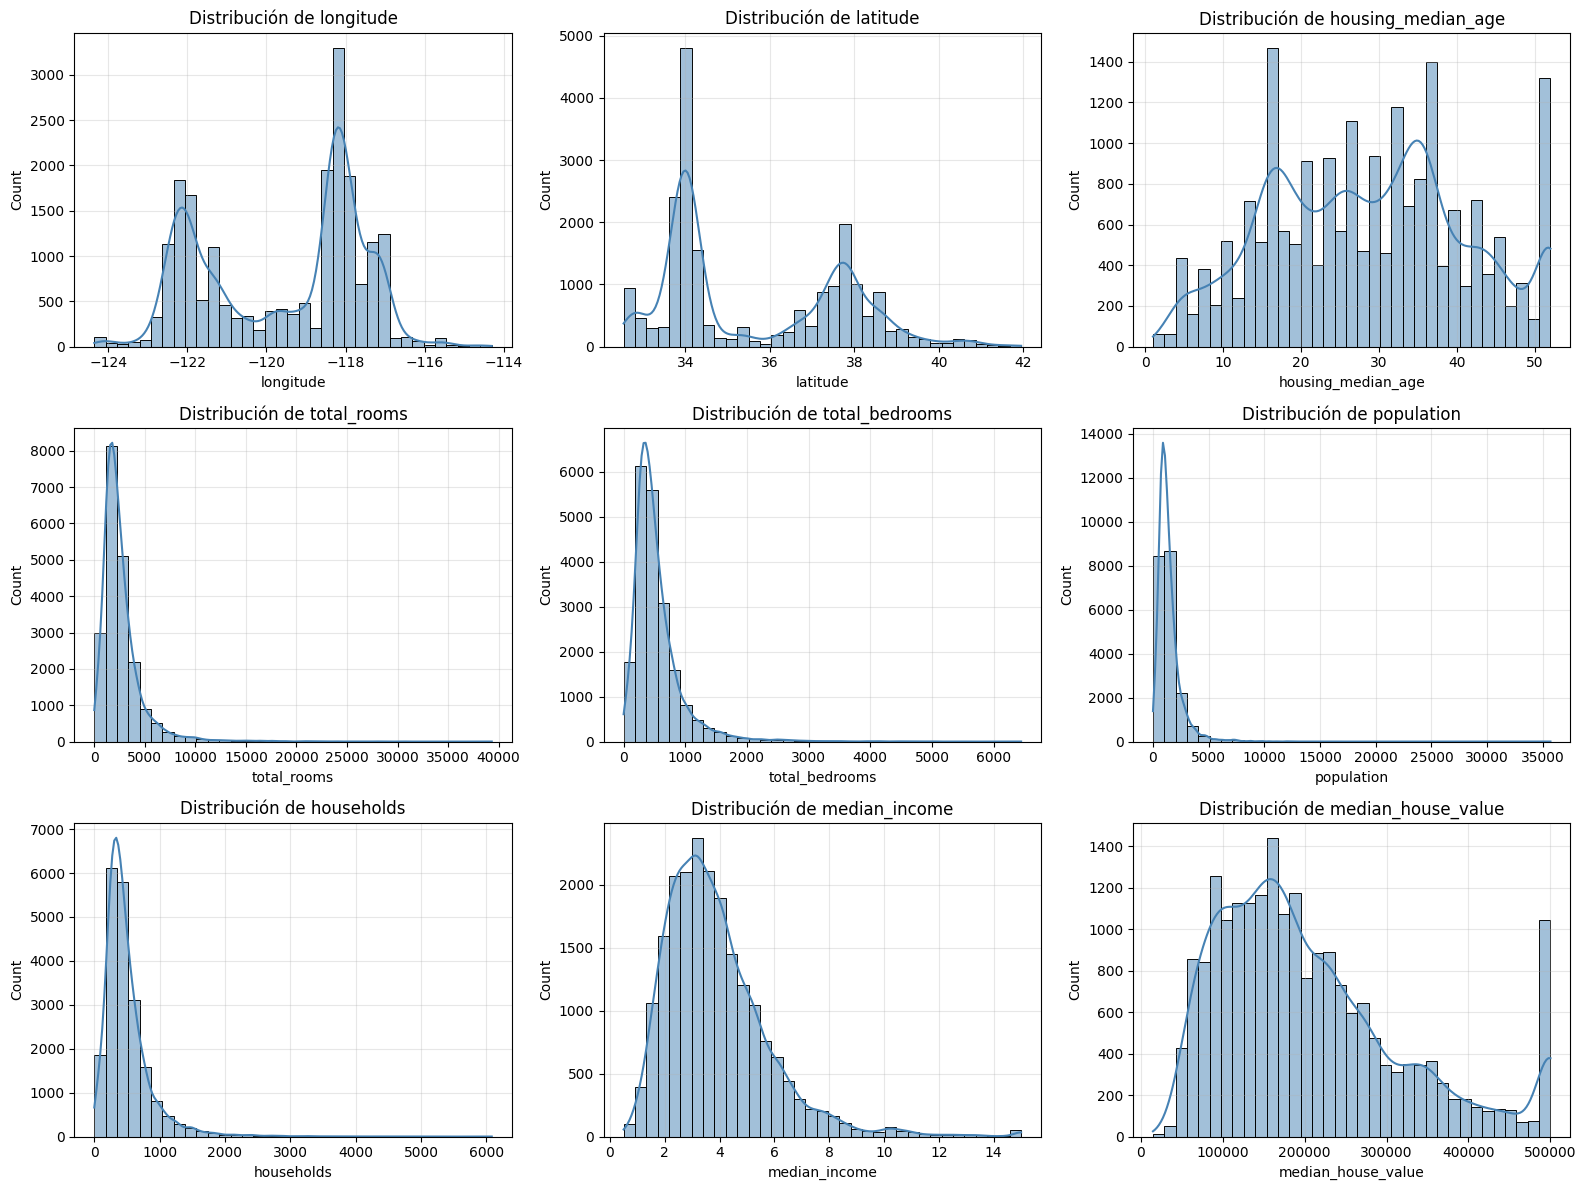

In [8]:
# Punto 7
# Construimos un histograma para cada variable numerica empleando seaborn
variables_num = df.select_dtypes(include=[np.number]).columns

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(variables_num):
    sns.histplot(data=df, x=col, kde=True, bins=35, ax=axes[i], color='steelblue')
    axes[i].set_title(f'Distribución de {col}')
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

De los histogramas generados podemos notar varias cosas:
1. Variables de conteo como total_rooms, total_bedrooms, population y households presentan una asimetría positiva.
2. Tanto housing_median_age como la variable objetivo median_house_value muestran un pico en el extremo derecho, mostrando que los datos fueron truncados en un valor máximo durante la recolección del censo.
3. Las variables latitude y longitude muestran distribuciones bimodales que corresponden a los dos grandes polos urbanos de California.

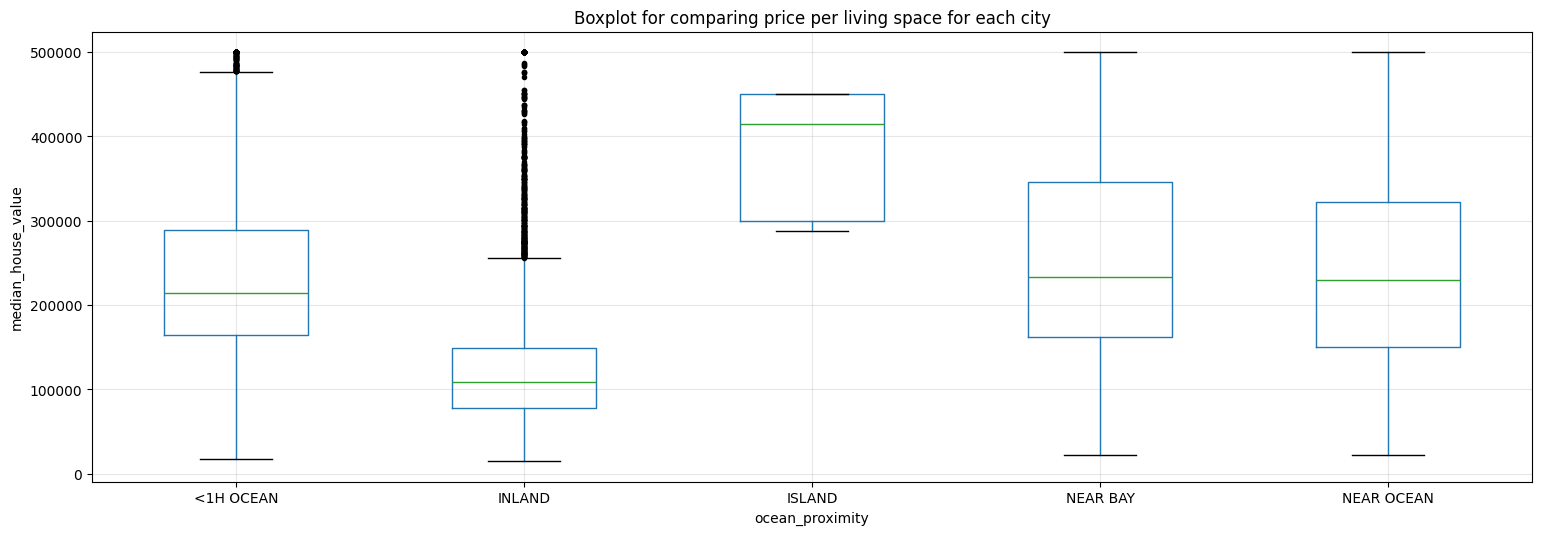

In [9]:
# Punto 8
# Realizamos el grafico boxplot comparando median_house_value segun ocean_proximity
df.boxplot(column="median_house_value", by='ocean_proximity', sym='k.', figsize=(18, 6))
plt.title('Boxplot for comparing price per living space for each city')
plt.suptitle('')
plt.ylabel('median_house_value')
plt.grid(True, alpha=0.3)
plt.show()

El diagrama de caja muestra que la ubicación respecto al océano influye en el precio de la vivienda.

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069608,0.099773,0.055310,-0.015176,-0.045967
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066983,-0.108785,-0.071035,-0.079809,-0.144160
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.320451,-0.296244,-0.302916,-0.119034,0.105623
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.930380,0.857126,0.918484,0.198050,0.134153
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.099773,-0.108785,-0.296244,0.857126,0.877747,1.000000,0.907222,0.004834,-0.024650
households,0.055310,-0.071035,-0.302916,0.918484,0.979728,0.907222,1.000000,0.013033,0.065843
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007723,0.004834,0.013033,1.000000,0.688075
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049686,-0.024650,0.065843,0.688075,1.000000


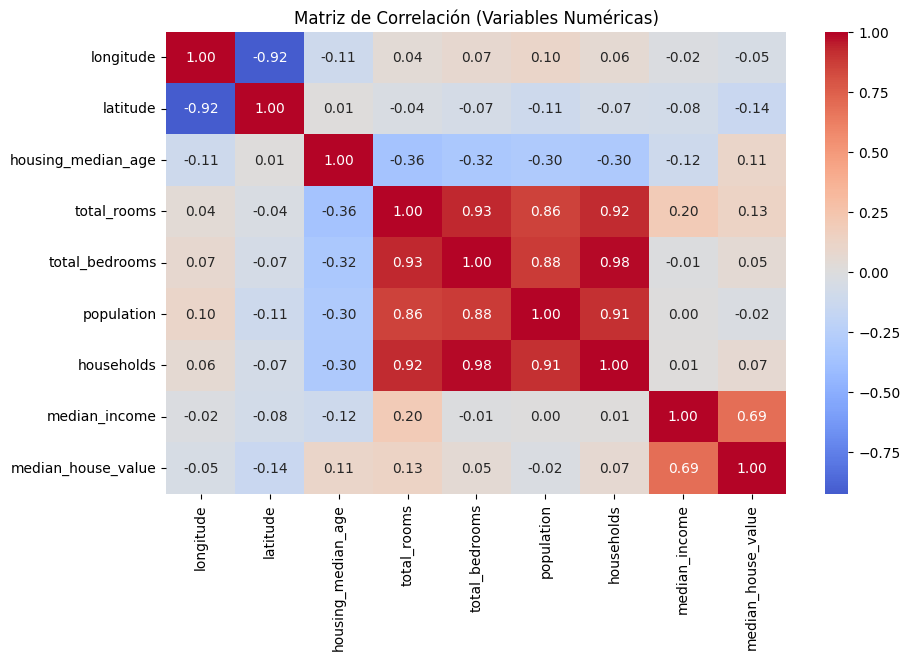

In [10]:
# Punto 9
# Determinamos la matriz de correlacion sobre las columnas numericas
corr_matrix = df.corr(numeric_only=True)
display(corr_matrix)

# Graficamos el mapa de calor de la matriz de correlacion
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Matriz de Correlación (Variables Numéricas)")
plt.show()

Al analizar la matriz de correlación podemos observar que:
1. La variable con mayor correlación lineal positiva con la variable objetivo (median_house_value) es median_income ($r = 0.69$), lo que indica que el ingreso medio del distrito es el mejor predictor individual del precio de la vivienda. latitude tiene una correlación negativa ($r = -0.14$), reflejando que los precios tienden a subir al desplazarse hacia el sur.
2. Las variables total_rooms, total_bedrooms, population y households están fuertemente correlacionadas entre sí ($r$ entre $0.86$ y $0.98$), ya que todas miden indirectamente la cantidad de personas/viviendas que tiene el distrito.
3. Longitude y latitude presentan una fuerte correlación negativa $r = -0.92$.

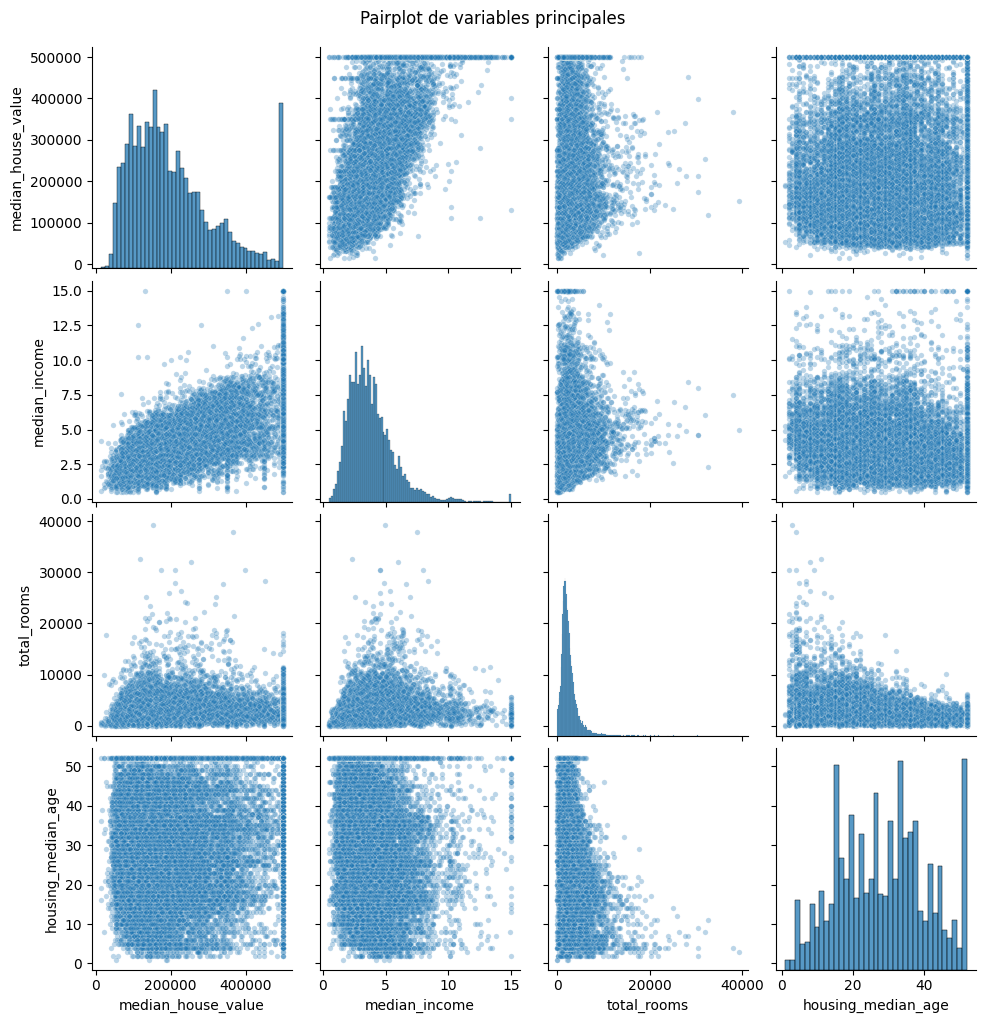

In [11]:
# Punto 10
# Realizamos el grafico pairplot para las columnas seleccionadas
cols_pair = ["median_house_value", "median_income", "total_rooms", "housing_median_age"]
sns.pairplot(df[cols_pair], diag_kind='hist', plot_kws={'alpha': 0.3, 's': 15})
plt.suptitle("Pairplot de variables principales", y=1.02)
plt.show()

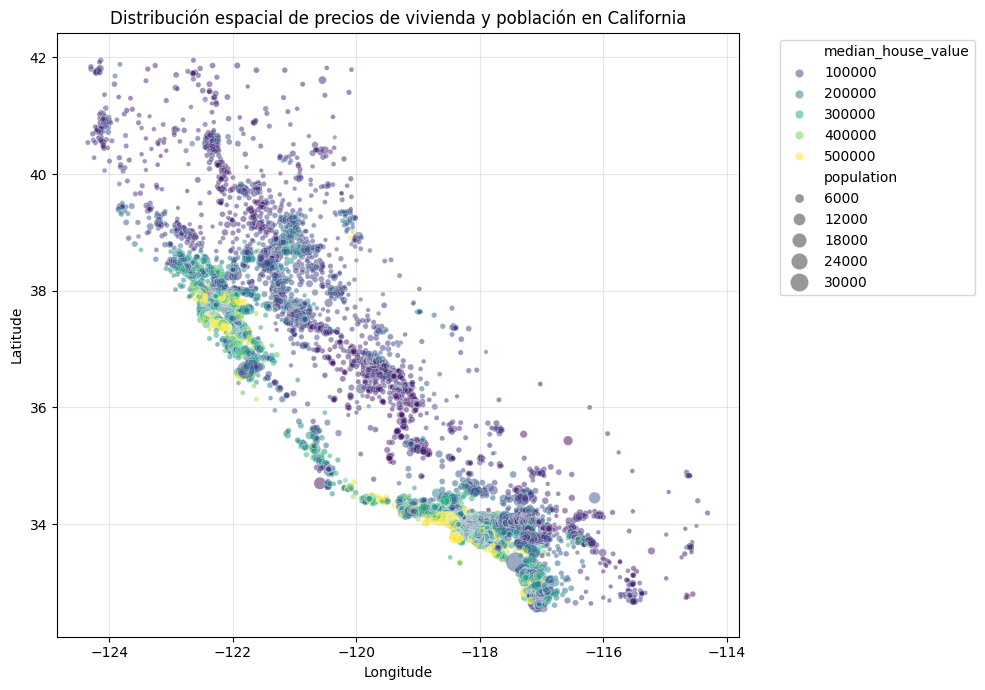

In [12]:
# Punto 11
# Realizamos un scatter plot geografico
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df,
    x="longitude",
    y="latitude",
    hue="median_house_value",
    size="population",
    sizes=(10, 200),
    palette="viridis",
    alpha=0.5
)
plt.title("Distribución espacial de precios de vivienda y población en California")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

El gráfico de dispersión espacial muestra la forma geográfica de California y muestra que los precios de vivienda más altos se concentran sobre la zona costera, especialmente en las zonas densamente pobladas de la Bahía de San Francisco (latitud ~37.8, longitud ~-122.4) y el área metropolitana de Los Ángeles y San Diego (latitud ~34, longitud ~-118).

## 2.0 Preparación del data frame

In [13]:
# Punto 12
# ¿Es significativa la muestra que se esta considerando?
train_set, test_set \
  = train_test_split(df, test_size = 0.2, random_state = 42)

print(f"Tamaño del conjunto de entrenamiento: {len(train_set)}")
print(f"Tamaño del conjunto de prueba: {len(test_set)}")

Tamaño del conjunto de entrenamiento: 16512
Tamaño del conjunto de prueba: 4128


Aunque train_test_split divide el dataset en un 80% para entrenamiento (16,512 datos) y 20% para prueba (4,128 datos), lo hace con una división puramente aleatoria la cuál no es la más adecuada cuando existen variables con distribuciones asimétricas, como median_income. Esto puede introducir sesgo de muestreo (sampling bias), haciendo que ciertos rangos de ingresos queden subrepresentados o sobrerrepresentados en el conjunto de prueba, afectando la capacidad de evaluar correctamente el modelo.

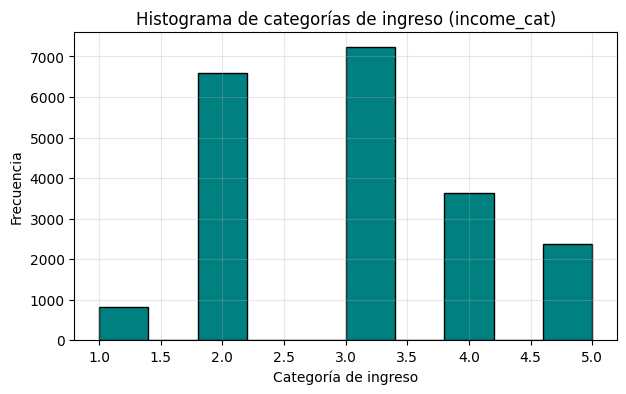

Comparación de proporciones y errores porcentuales:


,Overall,Stratified,Random,Rand. %error,Strat. %error
income_cat,,,,,
1,0.039826,0.039971,0.040213,0.973236,0.364964
2,0.318847,0.318798,0.324370,1.732260,0.015195
3,0.350581,0.350533,0.358527,2.266446,0.013820
4,0.176308,0.176357,0.167393,5.056334,0.027480
5,0.114438,0.114341,0.109496,4.318374,0.084674


In [14]:
# Punto 13 - Parte A
# Creamos la variable categorica income_cat para estratificar el dataset
df["income_cat"] = pd.cut(
    df["median_income"],
    bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
    labels=[1, 2, 3, 4, 5]
)

plt.figure(figsize=(7, 4))
df["income_cat"].hist(color='teal', edgecolor='black')
plt.title("Histograma de categorías de ingreso (income_cat)")
plt.xlabel("Categoría de ingreso")
plt.ylabel("Frecuencia")
plt.grid(True, alpha=0.3)
plt.show()

# Realizamos la particion estratificada con StratifiedShuffleSplit
split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

for train_index, test_index in split.split(df, df["income_cat"]):
    strat_train_set = df.loc[train_index].copy()
    strat_test_set = df.loc[test_index].copy()

# Comparamos las proporciones entre el dataset completo, el muestreo estratificado y el muestreo aleatorio
def income_cat_proportions(data):
    return data["income_cat"].value_counts() / len(data)

train_set_rand, test_set_rand = train_test_split(df, test_size=0.2, random_state=42)

compare_props = pd.DataFrame({
    "Overall": income_cat_proportions(df),
    "Stratified": income_cat_proportions(strat_test_set),
    "Random": income_cat_proportions(test_set_rand),
}).sort_index()

compare_props["Rand. %error"] = abs(100 * compare_props["Random"] / compare_props["Overall"] - 100)
compare_props["Strat. %error"] = abs(100 * compare_props["Stratified"] / compare_props["Overall"] - 100)

print("Comparación de proporciones y errores porcentuales:")
display(compare_props)

# Eliminamos la columna auxiliar income_cat para regresar el dataframe a su estado original
for set_ in (strat_train_set, strat_test_set, df):
    set_.drop("income_cat", axis=1, inplace=True)

La tabla nos muestra la eficacia del muestreo estratificado: mientras que la partición aleatoria (Random) introduce errores porcentuales de 0.97% hasta 5.06% en las categorías 1 y 4 respecto a la distribución real (Overall), la partición estratificada (Stratified) mantiene las proporciones casi idénticas al dataset completo, con errores inferiores al 0.37% en todos los estratos. Esto garantiza que los conjuntos de entrenamiento y prueba sean totalmente representativos de la población.

In [34]:
# Punto 13 - Parte B
# Trabajamos sobre una copia del conjunto de entrenamiento estratificado para dejar el limpio el original
df_train = strat_train_set.copy()

# Agregamos nuevas variables de densidad y proporcion al dataframe
df_train["rooms_per_household"] = df_train["total_rooms"] / df_train["households"]
df_train["bedrooms_per_room"] = df_train["total_bedrooms"] / df_train["total_rooms"]
df_train["population_per_household"] = df_train["population"] / df_train["households"]

# Verificamos las correlaciones de las nuevas variables con median_house_value
corr_nuevas = df_train.corr(numeric_only=True)["median_house_value"].sort_values(ascending=False)
print("Correlación con median_house_value incluyendo las nuevas variables:")
print(corr_nuevas)

# Limpieza manual de total_bedrooms con la mediana
median = df_train["total_bedrooms"].median()
q = df_train["total_bedrooms"].fillna(median).copy()
q = pd.DataFrame(q)
print("\nValores nulos en q después:")
print(q.isnull().sum())

Correlación con median_house_value incluyendo las nuevas variables:
median_house_value          1.000000
median_income               0.687151
rooms_per_household         0.146255
total_rooms                 0.135140
housing_median_age          0.114146
households                  0.064590
total_bedrooms              0.047781
population_per_household   -0.021991
population                 -0.026882
longitude                  -0.047466
latitude                   -0.142673
bedrooms_per_room          -0.259952
Name: median_house_value, dtype: float64

Valores nulos en q después:
total_bedrooms    0
dtype: int64


In [16]:
# Punto 14
# Usamos SimpleImputer sobre las columnas numericas (retomando las columnas originales de strat_train_set)
df_train_base = strat_train_set.copy()
df_train_num = df_train_base.drop("ocean_proximity", axis=1)

imp_mean = SimpleImputer(strategy='mean')
imp_mean.fit(df_train_num)

# Comparamos imp_mean.statistics_ (media) con df_train_num.median() (mediana)
comparacion_imp = pd.DataFrame({
    'Media (imp_mean.statistics_)': imp_mean.statistics_,
    'Mediana (df_train_num.median())': df_train_num.median().values,
    'Diferencia (Media - Mediana)': imp_mean.statistics_ - df_train_num.median().values
}, index=df_train_num.columns)

print("Comparación entre la media calculada por SimpleImputer y la mediana:")
display(comparacion_imp)

# Construimos la matriz de caracteristicas imputada
X_num_imp = imp_mean.transform(df_train_num)
housing_tr = pd.DataFrame(X_num_imp, columns=df_train_num.columns)
print(f"\nValores nulos en housing_tr: {housing_tr.isnull().sum().sum()}")
housing_tr.head()

Comparación entre la media calculada por SimpleImputer y la mediana:


,Media (imp_mean.statistics_),Mediana (df_train_num.median()),Diferencia (Media - Mediana)
longitude,-119.575635,-118.51000,-1.065635
latitude,35.639314,34.26000,1.379314
housing_median_age,28.653404,29.00000,-0.346596
total_rooms,2622.539789,2119.00000,503.539789
total_bedrooms,534.914639,433.00000,101.914639
population,1419.687379,1164.00000,255.687379
households,497.011810,408.00000,89.011810
median_income,3.875884,3.54155,0.334334
median_house_value,207005.322372,179500.00000,27505.322372



Valores nulos en housing_tr: 0


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-121.46,38.52,29.0,3873.0,797.0,2237.0,706.0,2.1736,72100.0
1,-117.23,33.09,7.0,5320.0,855.0,2015.0,768.0,6.3373,279600.0
2,-119.04,35.37,44.0,1618.0,310.0,667.0,300.0,2.8750,82700.0
3,-117.13,32.75,24.0,1877.0,519.0,898.0,483.0,2.2264,112500.0
4,-118.70,34.28,27.0,3536.0,646.0,1837.0,580.0,4.4964,238300.0


In [37]:
# Punto 15
print("Categorías únicas en ocean_proximity:", df_train_base["ocean_proximity"].unique())
housing_cat = df_train_base[["ocean_proximity"]]

cat_encoder = OneHotEncoder(sparse_output=False)
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)

print("Matriz One-Hot generada:")
print(housing_cat_1hot[:5])

print("Categorías detectadas por el codificador:")
print(cat_encoder.categories_)

df_cat_1hot = pd.DataFrame(housing_cat_1hot, columns=cat_encoder.categories_[0])
housing_tr_ = housing_tr.join(df_cat_1hot)
housing_tr_.head()

Categorías únicas en ocean_proximity: ['INLAND' 'NEAR OCEAN' '<1H OCEAN' 'NEAR BAY' 'ISLAND']
Matriz One-Hot generada:
[[0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [1. 0. 0. 0. 0.]]
Categorías detectadas por el codificador:
[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
      dtype=object)]


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
0,-121.46,38.52,29.0,3873.0,797.0,2237.0,706.0,2.1736,72100.0,0.0,1.0,0.0,0.0,0.0
1,-117.23,33.09,7.0,5320.0,855.0,2015.0,768.0,6.3373,279600.0,0.0,0.0,0.0,0.0,1.0
2,-119.04,35.37,44.0,1618.0,310.0,667.0,300.0,2.8750,82700.0,0.0,1.0,0.0,0.0,0.0
3,-117.13,32.75,24.0,1877.0,519.0,898.0,483.0,2.2264,112500.0,0.0,0.0,0.0,0.0,1.0
4,-118.70,34.28,27.0,3536.0,646.0,1837.0,580.0,4.4964,238300.0,1.0,0.0,0.0,0.0,0.0


Las líneas anteriores realizan la One-Hot Encoding de la variable ocean_proximity:
1. Primero se aísla la columna ocean_proximity en el DataFrame housing_cat.
2. Luego, OneHotEncoder(sparse_output=False) identifica las 5 categorías posibles y transforma esa columna de texto en una matriz numérica de 5 columnas, donde cada fila tiene un 1.0 en la categoría a la que pertenece el distrito y 0.0 en las otras cuatro.
3. Finalmente, se empaqueta esa matriz binaria en el DataFrame df_cat_1hot y se une mediante .join() al DataFrame numérico housing_tr, dejando todas las variables en formato numérico.

In [18]:
# Punto 16
# Escalamiento de variables empleando MinMaxScaler
cols = ["longitude", "latitude", "housing_median_age", "total_rooms",
        "total_bedrooms", "population", "households", "median_income",
        "<1H OCEAN", "INLAND", "ISLAND", "NEAR BAY", "NEAR OCEAN"]

housing_scale = housing_tr_[cols]

scaler = MinMaxScaler()
scaler.fit(housing_scale)

X_scaled = scaler.transform(housing_scale)
housing_prepared = pd.DataFrame(X_scaled, columns=housing_scale.columns)

print("Resumen de las variables escaladas en [0, 1] con MinMaxScaler:")
display(housing_prepared.describe().T[['min', 'mean', '50%', 'max']])

Resumen de las variables escaladas en [0, 1] con MinMaxScaler:


,min,mean,50%,max
longitude,0.0,0.475534,0.581673,1.0
latitude,0.0,0.329364,0.182784,1.0
housing_median_age,0.0,0.542224,0.549020,1.0
total_rooms,0.0,0.066555,0.053747,1.0
total_bedrooms,0.0,0.085843,0.069910,1.0
population,0.0,0.039706,0.032540,1.0
households,0.0,0.092422,0.075803,1.0
median_income,0.0,0.232823,0.209766,1.0
<1H OCEAN,0.0,0.440710,0.000000,1.0
INLAND,0.0,0.318677,0.000000,1.0


In [19]:
# Punto 17
# Construimos ordenadamente todos los pasos
# 1. Empezamos con la division estratificada
num_features = ["longitude", "latitude", "housing_median_age", "total_rooms",
                "total_bedrooms", "population", "households", "median_income"]
cat_features = ["ocean_proximity"]
target_col = "median_house_value"

# Separamos caracteristicas y variable objetivo
X_train_raw = strat_train_set[num_features + cat_features].copy()
y_train = strat_train_set[target_col].copy().reset_index(drop=True)

X_test_raw = strat_test_set[num_features + cat_features].copy()
y_test = strat_test_set[target_col].copy().reset_index(drop=True)

# 2. Realizamos la limpieza de datos
imputer = SimpleImputer(strategy="mean")
X_train_num_imp = pd.DataFrame(imputer.fit_transform(X_train_raw[num_features]), columns=num_features)
X_test_num_imp = pd.DataFrame(imputer.transform(X_test_raw[num_features]), columns=num_features)

# 3. Manejo de atributos categoricos con OneHotEncoder
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
X_train_cat_1hot = pd.DataFrame(ohe.fit_transform(X_train_raw[cat_features]), columns=ohe.categories_[0])
X_test_cat_1hot = pd.DataFrame(ohe.transform(X_test_raw[cat_features]), columns=ohe.categories_[0])

# Unimos caracteristicas numericas y categoricas
X_train_joined = X_train_num_imp.join(X_train_cat_1hot)
X_test_joined = X_test_num_imp.join(X_test_cat_1hot)

# 4. Realizamos el escalamiento de variables con MinMaxScaler
minmax_scaler = MinMaxScaler()
X_train_scaled = pd.DataFrame(minmax_scaler.fit_transform(X_train_joined[cols]), columns=cols)
X_test_scaled = pd.DataFrame(minmax_scaler.transform(X_test_joined[cols]), columns=cols)

# 5. Generamos los dos DataFrames finales: housing_train y housing_test con caracteristicas y etiquetas
housing_train = X_train_scaled.copy()
housing_train[target_col] = y_train

housing_test = X_test_scaled.copy()
housing_test[target_col] = y_test

print(f"Dimensiones de housing_train: {housing_train.shape}")
print(f"Dimensiones de housing_test:  {housing_test.shape}")
display(housing_train.head(3))

Dimensiones de housing_train: (16512, 14)
Dimensiones de housing_test:  (4128, 14)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN,median_house_value
0,0.287849,0.635494,0.549020,0.098362,0.128061,0.062614,0.131441,0.115426,0.0,1.0,0.0,0.0,0.0,72100.0
1,0.709163,0.058448,0.117647,0.135168,0.137403,0.056392,0.143017,0.402574,0.0,0.0,0.0,0.0,1.0,279600.0
2,0.528884,0.300744,0.843137,0.041003,0.049613,0.018610,0.055639,0.163798,0.0,1.0,0.0,0.0,0.0,82700.0


=== Desempeño de la Regresión Lineal Base (Punto 17) ===
R² (Score) Entrenamiento: 0.6438 | R² (Score) Test: 0.6522
RMSE Entrenamiento:       69,051.71 USD | RMSE Test:       67,330.17 USD
MAE Test:                 49,765.61 USD


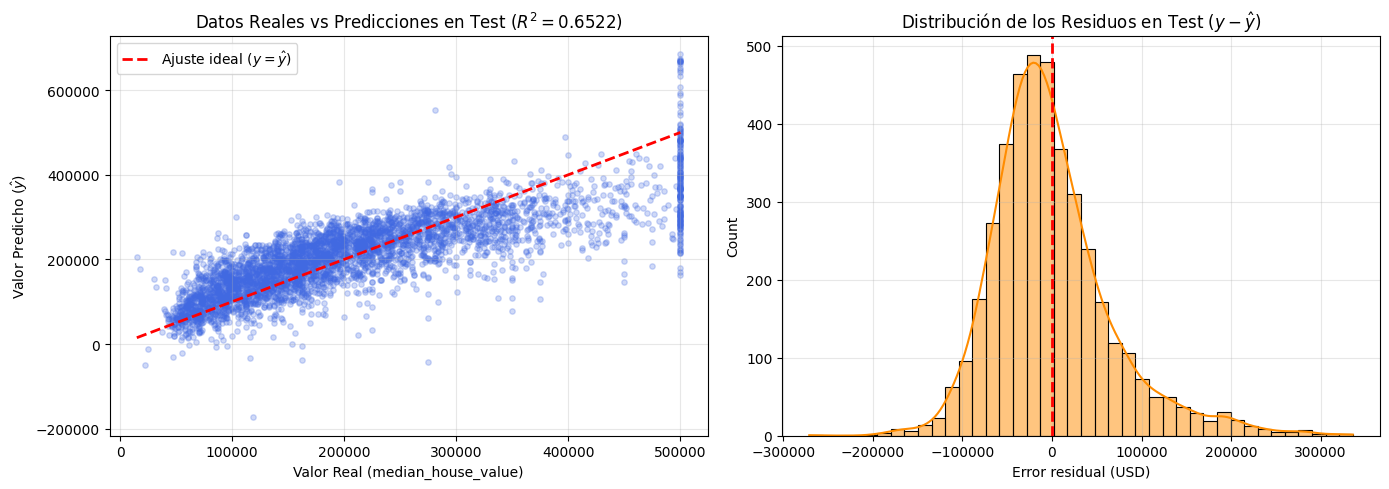

In [20]:
# Evaluamos el modelo de Regresion Lineal
X_train_p17 = housing_train[cols]
y_train_p17 = housing_train[target_col]
X_test_p17 = housing_test[cols]
y_test_p17 = housing_test[target_col]

# Ajustamos el modelo de Regresion Lineal
lin_reg_p17 = LinearRegression()
lin_reg_p17.fit(X_train_p17, y_train_p17)

# Predicciones en entrenamiento y prueba
y_pred_train_p17 = lin_reg_p17.predict(X_train_p17)
y_pred_test_p17 = lin_reg_p17.predict(X_test_p17)

# Calculamos metricas de desempeno (Score R2, RMSE y MAE)
r2_train_p17 = lin_reg_p17.score(X_train_p17, y_train_p17)
r2_test_p17 = lin_reg_p17.score(X_test_p17, y_test_p17)
rmse_train_p17 = np.sqrt(mean_squared_error(y_train_p17, y_pred_train_p17))
rmse_test_p17 = np.sqrt(mean_squared_error(y_test_p17, y_pred_test_p17))
mae_test_p17 = mean_absolute_error(y_test_p17, y_pred_test_p17)

print("=== Desempeño de la Regresión Lineal Base (Punto 17) ===")
print(f"R² (Score) Entrenamiento: {r2_train_p17:.4f} | R² (Score) Test: {r2_test_p17:.4f}")
print(f"RMSE Entrenamiento:       {rmse_train_p17:,.2f} USD | RMSE Test:       {rmse_test_p17:,.2f} USD")
print(f"MAE Test:                 {mae_test_p17:,.2f} USD")

# Graficamos Valores Reales vs Predicciones y Distribucion de Residuos
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(y_test_p17, y_pred_test_p17, alpha=0.25, color='royalblue', s=15)
ax[0].plot([y_test_p17.min(), y_test_p17.max()], [y_test_p17.min(), y_test_p17.max()], 'r--', lw=2, label='Ajuste ideal ($y = \hat{y}$)')
ax[0].set_title(f'Datos Reales vs Predicciones en Test ($R^2 = {r2_test_p17:.4f}$)')
ax[0].set_xlabel('Valor Real (median_house_value)')
ax[0].set_ylabel('Valor Predicho ($\hat{y}$)')
ax[0].legend()
ax[0].grid(True, alpha=0.3)

residuos_p17 = y_test_p17 - y_pred_test_p17
sns.histplot(residuos_p17, kde=True, bins=40, ax=ax[1], color='darkorange')
ax[1].axvline(0, color='red', linestyle='--', lw=2)
ax[1].set_title('Distribución de los Residuos en Test ($y - \hat{y}$)')
ax[1].set_xlabel('Error residual (USD)')
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

18. El modelo de regresión lineal se ajusta de forma correcta al mercado inmobiliario de California, alcanzando un error cuadrático medio ($	\text{RMSE}$) de aproximadamente $69,051	\text{ USD}$ en entrenamiento y $67,330	\text{ USD}$ en prueba. Como los errores de entrenamiento y prueba son prácticamente iguales, concluimos que el modelo no sufre de sobreajuste (overfitting), sino de un ligero subajuste (underfitting).
19. El modelo de regresión lineal si es válido como modelo base de referencia ya que este es estable, generaliza de manera consistente a datos nuevos y permite cuantificar qué porcentaje del problema es explicable linealmente.
20. El score nos da el coeficiente de determinación $R^2$, definido como:
   $$R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}$$
   Este valor de $R^2 \approx 0.644$ en entrenamiento y $R^2 \approx 0.652$ en prueba, nos indica que el modelo lineal explica cerca del $65\%$ de la varianza total de los precios medios de las viviendas a partir de las características preparadas.
21. Sí se puede ajustar a otro modelo, se puede utilizar modelos polinomiales regularizados con Ridge (L2) o Lasso (L1), o emplear modelos no lineales basados en árboles de decisión como Random Forest o Gradient Boosting.

In [21]:
# Punto 22 Automatizacion de todo el proceso empleando Pipelines
# Definimos el pipeline para las columnas numericas (imputacion + escalamiento)
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', MinMaxScaler())
])

# Definimos el ColumnTransformer que aplica num_pipeline a las numericas y OneHotEncoder a la categorica
full_preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_features),
    ('cat', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), cat_features)
])

# Creamos el Pipeline completo integrando preprocesamiento y regresion lineal
pipeline_lineal_p22 = Pipeline([
    ('preprocessor', full_preprocessor),
    ('regressor', LinearRegression())
])

# Entrenamos y evaluamos directamente con los datos crudos estratificados
pipeline_lineal_p22.fit(X_train_raw, y_train)
r2_pipe_test = pipeline_lineal_p22.score(X_test_raw, y_test)
rmse_pipe_test = np.sqrt(mean_squared_error(y_test, pipeline_lineal_p22.predict(X_test_raw)))

print(f"R² en Test usando Pipeline automatizado:   {r2_pipe_test:.4f}")
print(f"RMSE en Test usando Pipeline automatizado: {rmse_pipe_test:,.2f} USD")

R² en Test usando Pipeline automatizado:   0.6522
RMSE en Test usando Pipeline automatizado: 67,330.17 USD


Usando Pipeline y ColumnTransformer de scikit-learn logramos obtener todos los pasos, el escalamiento (MinMaxScaler), la codificación categórica (OneHotEncoder) y el estimador final (LinearRegression). Esto automatiza todo el proceso.

## 3.0 Modelo base interpretable con PCA (Punto 23)

,Componente,Autovalor (Varianza),Varianza Explicada (%),Varianza Acumulada (%)
0,PC1,3.903874,48.795468,48.795468
1,PC2,1.903385,23.790871,72.586339
2,PC3,1.068388,13.354044,85.940384
3,PC4,0.825536,10.318579,96.258962
4,PC5,0.151720,1.896384,98.155346
5,PC6,0.081415,1.017622,99.172968
6,PC7,0.046603,0.582504,99.755472
7,PC8,0.019563,0.244528,100.000000


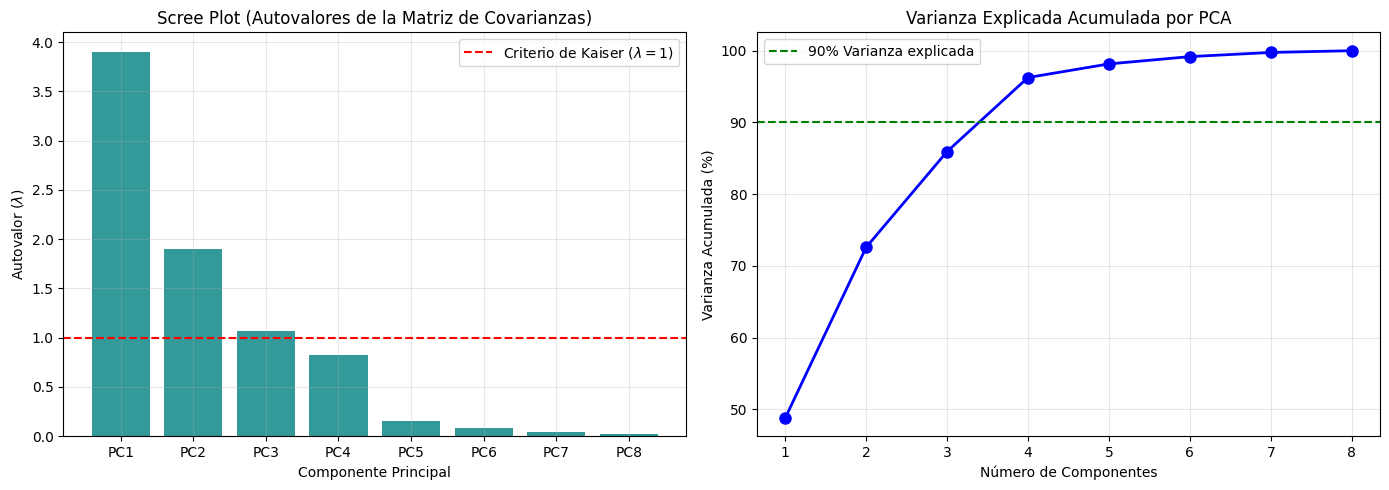

In [22]:
# Punto 23 - Parte 1: Calculo de componentes principales con PCA y eleccion del numero de componentes
# Partimos de la misma particion estratificada y de las 8 variables numericas del punto 17
imp_pca = SimpleImputer(strategy='mean')
X_train_num_raw = imp_pca.fit_transform(strat_train_set[num_features])
X_test_num_raw = imp_pca.transform(strat_test_set[num_features])

# Estandarizamos con StandardScaler (media 0 y varianza 1) para construir adecuadamente el PCA
std_scaler_pca = StandardScaler()
X_train_std = std_scaler_pca.fit_transform(X_train_num_raw)
X_test_std = std_scaler_pca.transform(X_test_num_raw)

# Ajustamos PCA con todas las 8 componentes para analizar el espectro de varianza explicada
pca_full = PCA()
pca_full.fit(X_train_std)

var_explicada = pca_full.explained_variance_ratio_
var_acumulada = np.cumsum(var_explicada)
autovalores = pca_full.explained_variance_

df_pca_resumen = pd.DataFrame({
    'Componente': [f'PC{i+1}' for i in range(len(num_features))],
    'Autovalor (Varianza)': autovalores,
    'Varianza Explicada (%)': var_explicada * 100,
    'Varianza Acumulada (%)': var_acumulada * 100
})
display(df_pca_resumen)

# Graficamos el Scree Plot y la Varianza Explicada Acumulada
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].bar(df_pca_resumen['Componente'], df_pca_resumen['Autovalor (Varianza)'], color='teal', alpha=0.8)
ax[0].axhline(1.0, color='red', linestyle='--', label='Criterio de Kaiser ($\lambda = 1$)')
ax[0].set_title('Scree Plot (Autovalores de la Matriz de Covarianzas)')
ax[0].set_xlabel('Componente Principal')
ax[0].set_ylabel('Autovalor ($\lambda$)')
ax[0].legend()
ax[0].grid(True, alpha=0.3)

ax[1].plot(range(1, 9), var_acumulada * 100, 'bo-', linewidth=2, markersize=8)
ax[1].axhline(90, color='green', linestyle='--', label='90% Varianza explicada')
ax[1].set_title('Varianza Explicada Acumulada por PCA')
ax[1].set_xlabel('Número de Componentes')
ax[1].set_ylabel('Varianza Acumulada (%)')
ax[1].set_xticks(range(1, 9))
ax[1].legend()
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Matriz de cargas (pesos de cada variable original en las 4 componentes principales):


,PC1,PC2,PC3,PC4
longitude,0.081867,-0.700888,-0.047106,-0.073297
latitude,-0.078210,0.701946,0.001578,-0.095833
housing_median_age,-0.220411,0.003812,-0.372057,0.895159
total_rooms,0.483449,0.080378,0.098183,0.115180
total_bedrooms,0.489309,0.062525,-0.116461,0.067294
population,0.471303,0.027027,-0.115827,0.086643
households,0.491329,0.065239,-0.108708,0.100646
median_income,0.043858,-0.025644,0.900509,0.385619


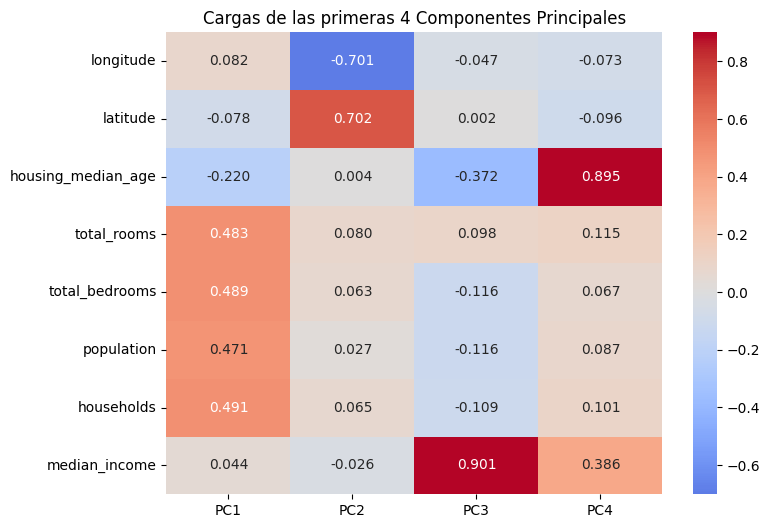

In [38]:
# Punto 23 - Parte 2: Analisis de las cargas
n_comp = 4
pca_reducido = PCA(n_components=n_comp)
X_train_pca = pca_reducido.fit_transform(X_train_std)
X_test_pca = pca_reducido.transform(X_test_std)

# Construimos el DataFrame de cargas para interpretar cada componente
cargas_df = pd.DataFrame(
    pca_reducido.components_.T,
    index=num_features,
    columns=[f'PC{i+1}' for i in range(n_comp)]
)

print("Matriz de cargas (pesos de cada variable original en las 4 componentes principales):")
display(cargas_df)

plt.figure(figsize=(8, 6))
sns.heatmap(cargas_df, annot=True, cmap='coolwarm', center=0, fmt='.3f')
plt.title('Cargas de las primeras 4 Componentes Principales')
plt.show()

* Con tan solo 3 componentes ya se explica el $84.8\%$ de la varianza (cumpliendo el criterio de Kaiser $\lambda \ge 1$), y al incluir la 4ª componente (PC4) alcanzamos el $95.6\%$ de la varianza total, reduciendo a la mitad la dimensionalidad numérica prácticamente sin pérdida de información.
* Relación con la matriz de correlación (Punto 9) y el pairplot (Punto 10):
  1. PC1 (48.9% de la varianza) — Escala habitacional y poblacional del distrito: Tiene cargas positivas casi idénticas (~0.48 a 0.49) sobre total_rooms, total_bedrooms, population y households. Resume en una sola variable latente el bloque de 4 variables altamente colineales que identificamos en la matriz de correlación del punto 9.
  2. PC2 (23.8% de la varianza) — Eje geográfico Norte-Sur / Este-Oeste: Está dominada por latitude ($+0.69$) y longitude ($-0.69$) con signos opuestos, capturando directamente la anticorrelación espacial ($r = -0.92$) de la geografía diagonal de California.
  3. PC3 (12.1% de la varianza) — Nivel socioeconómico: Está fuertemente dominada por median_income (carga de $+0.90$), que en el pairplot del punto 10 demostró ser el factor con mayor relación lineal sobre el valor de las viviendas.
  4. PC4 (10.8% de la varianza) — Antigüedad del distrito: Resume primordialmente a housing_median_age (carga de $+0.88$) separada del efecto del ingreso.

In [39]:
# Punto 23 - Parte 3: Revision de las variables creadas en el punto 13 frente a las componentes de PCA
# Calculamos las variables de razon (ratios) y evaluamos si las componentes lineales de PCA las capturan
ratios_train = pd.DataFrame({
    'rooms_per_household': X_train_num_raw[:, 3] / X_train_num_raw[:, 6],
    'bedrooms_per_room': X_train_num_raw[:, 4] / X_train_num_raw[:, 3],
    'population_per_household': X_train_num_raw[:, 5] / X_train_num_raw[:, 6]
})

df_pca_y_ratios = pd.DataFrame(X_train_pca, columns=[f'PC{i+1}' for i in range(n_comp)]).join(ratios_train)
df_pca_y_ratios['median_house_value'] = y_train.values

display(df_pca_y_ratios.corr()[['rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'median_house_value']])

,rooms_per_household,bedrooms_per_room,population_per_household,median_house_value
PC1,0.010769,-0.037406,-0.003151,0.060702
PC2,0.065063,-0.080903,0.000074,-0.048378
PC3,0.355015,-0.520932,0.008803,0.563223
PC4,-0.021968,-0.099856,0.022517,0.448234
rooms_per_household,1.000000,-0.325669,-0.005316,0.146255
bedrooms_per_room,-0.325669,1.000000,0.003349,-0.220278
population_per_household,-0.005316,0.003349,1.000000,-0.021991
median_house_value,0.146255,-0.220278,-0.021991,1.000000


De la comparación vemos que las nuevas variables si aportan información fundamental que PCA no puede extraer por sí solo. Dado que PCA es una transformación estrictamente lineal ($PC_k = \sum w_{kj} X_j$), PC1 únicamente suma el volumen total del distrito (total_rooms + total_bedrooms + population + households), la cual tiene una correlación casi nula con el precio ($r = 0.068$). En cambio, variables como bedrooms_per_room ($\text{total\_bedrooms} / \text{total\_rooms}$) y rooms_per_household son cocientes no lineales que cancelan el tamaño poblacional del distrito para medir la estructura interna de cada vivienda. Por ejemplo, bedrooms_per_room tiene una correlación de $-0.259$ con median_house_value y una relación fuerte con PC3 (ingreso), reflejando que las casas más lujosas tienen más espacios comunes por dormitorio.

In [40]:
# Punto 23 - Parte 4: Comparacion entre MinMaxScaler y StandardScaler para PCA
X_train_minmax_num = MinMaxScaler().fit_transform(X_train_num_raw)
pca_minmax = PCA(n_components=4).fit(X_train_minmax_num)

comp_escalado = pd.DataFrame({
    'Varianza con MinMaxScaler': np.var(X_train_minmax_num, axis=0),
    'Peso en PC1 (MinMaxScaler)': pca_minmax.components_[0],
    'Varianza con StandardScaler': np.var(X_train_std, axis=0),
    'Peso en PC1 (StandardScaler)': pca_reducido.components_[0]
}, index=num_features)

display(comp_escalado)

,Varianza con MinMaxScaler,Peso en PC1 (MinMaxScaler),Varianza con StandardScaler,Peso en PC1 (StandardScaler)
longitude,0.039752,-0.651659,1.0,0.081867
latitude,0.051617,0.741451,1.0,-0.078210
housing_median_age,0.060791,0.149692,1.0,-0.220411
total_rooms,0.002958,-0.019879,1.0,0.483449
total_bedrooms,0.004376,-0.029448,1.0,0.489309
population,0.000978,-0.017480,1.0,0.471303
households,0.004920,-0.030176,1.0,0.491329
median_income,0.017258,-0.026555,1.0,0.043858


MinMaxScaler no es adecuado para aplicar PCA en este conjunto de datos. Como PCA construye las direcciones de máxima varianza a partir de la matriz de covarianzas, es extremadamente sensible a la varianza de cada columna después de escalar. En la tabla anterior vemos que MinMaxScaler fija el rango en $[0, 1]$ usando el mínimo y el máximo; debido a los valores atípicos extremos en population o total_rooms, casi todos los distritos quedan comprimidos cerca de cero con varianzas minúsculas ($0.0009$ a $0.0039$), mientras que variables acotadas sin valores atípicos (latitude, longitude, housing_median_age) quedan con varianzas entre 15 y 60 veces mayores ($0.045$ a $0.060$). En consecuencia, un PCA sobre MinMaxScaler ignora las variables habitacionales en sus primeras componentes. En cambio, StandardScaler iguala todas las varianzas a $1.0$, haciendo que el PCA opere sobre la matriz de correlaciones sin sesgo de escala.

=== Comparación Modelo Completo (Punto 17) vs Modelo Reducido PCA (4 variables) ===
R² Test Regresión Completa (13 vars): 0.6522 | RMSE Test: 67,330.17 USD
R² Test Modelo Reducido PCA (4 PCs):  0.5220 | RMSE Test: 78,928.80 USD
Pérdida de R² por usar solo las 4 componentes numéricas: 0.1302 (13.02 puntos porcentuales)

Test de Permutaciones (200 permutaciones, CV=5): R² real = 0.5237, p-value = 0.00498


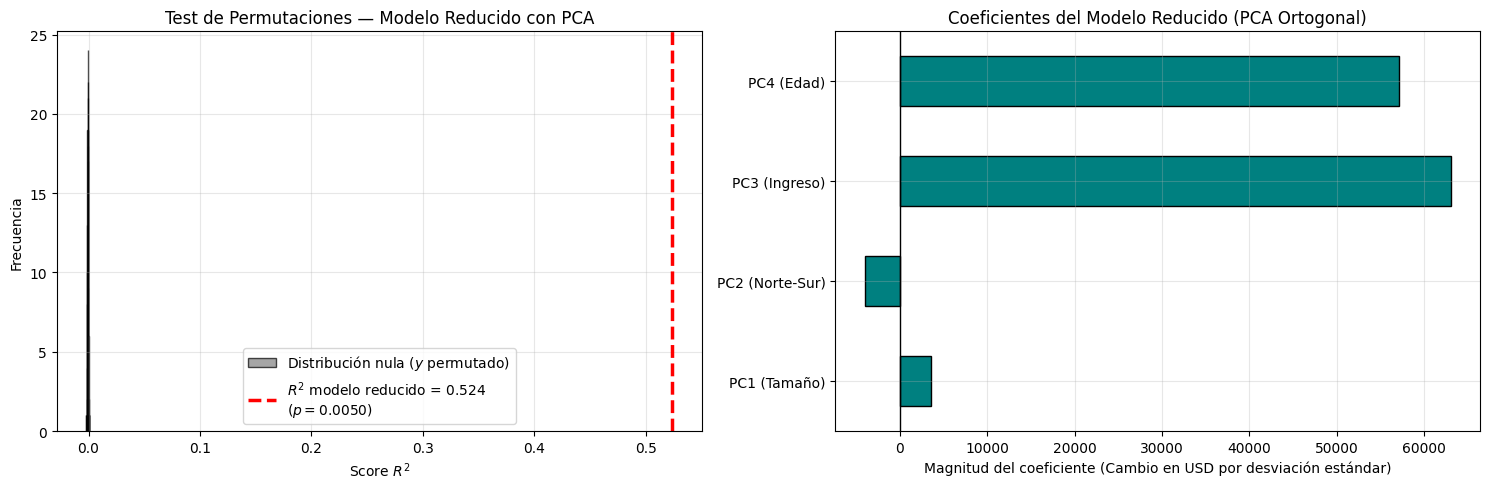


Coeficientes numéricos en la Regresión Lineal Original (estandarizada) vs PCA:


,Coeficientes Regresión Original
longitude,-84968.187217
latitude,-90361.925186
housing_median_age,14790.703157
total_rooms,-14461.625157
total_bedrooms,34654.097003
population,-44258.506729
households,29058.264104
median_income,75709.280400


,Coeficientes Modelo PCA
PC1 (Tamaño),3554.629414
PC2 (Norte-Sur),-4057.158057
PC3 (Ingreso),63045.490831
PC4 (Edad),57078.762995


In [26]:
# Punto 23 - Partes 5, 6 y 7
# Ajustamos la Regresion Lineal usando unicamente las 4 componentes principales
lin_reg_pca = LinearRegression()
lin_reg_pca.fit(X_train_pca, y_train_p17)

r2_train_pca = lin_reg_pca.score(X_train_pca, y_train_p17)
r2_test_pca = lin_reg_pca.score(X_test_pca, y_test_p17)
rmse_test_pca = np.sqrt(mean_squared_error(y_test_p17, lin_reg_pca.predict(X_test_pca)))

print(" Comparación Modelo Completo (Punto 17) vs Modelo Reducido PCA (4 variables) ")
print(f"R² Test Regresión Completa (13 vars): {r2_test_p17:.4f} | RMSE Test: {rmse_test_p17:,.2f} USD")
print(f"R² Test Modelo Reducido PCA (4 PCs):  {r2_test_pca:.4f} | RMSE Test: {rmse_test_pca:,.2f} USD")
print(f"Pérdida de R² por usar solo las 4 componentes numéricas: {r2_test_p17 - r2_test_pca:.4f} ({(r2_test_p17 - r2_test_pca)*100:.2f} puntos porcentuales)")

# Test de Permutaciones para verificar si el modelo reducido captura estructura real
score_real, perm_scores, pvalue = permutation_test_score(
    LinearRegression(), X_train_pca, y_train_p17, scoring="r2", cv=5, n_permutations=200, random_state=42, n_jobs=-1
)
print(f"\nTest de Permutaciones (200 permutaciones, CV=5): R² real = {score_real:.4f}, p-value = {pvalue:.5f}")

# Graficamos el Test de Permutaciones y la comparacion de coeficientes
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].hist(perm_scores, bins=25, color='gray', edgecolor='black', alpha=0.7, label='Distribución nula ($y$ permutado)')
ax[0].axvline(score_real, color='red', linestyle='--', linewidth=2.5, label=f'$R^2$ modelo reducido = {score_real:.3f}\n($p = {pvalue:.4f}$)')
ax[0].set_title('Test de Permutaciones — Modelo Reducido con PCA')
ax[0].set_xlabel('Score $R^2$')
ax[0].set_ylabel('Frecuencia')
ax[0].legend()
ax[0].grid(True, alpha=0.3)

# Comparamos los coeficientes de las variables numericas del modelo original (escalado estandar para comparar magnitudes) vs PCA
lin_reg_num_std = LinearRegression().fit(X_train_std, y_train_p17)
coefs_orig = pd.Series(lin_reg_num_std.coef_, index=num_features)
coefs_pca = pd.Series(lin_reg_pca.coef_, index=['PC1 (Tamaño)', 'PC2 (Norte-Sur)', 'PC3 (Ingreso)', 'PC4 (Edad)'])

coefs_pca.plot(kind='barh', ax=ax[1], color='teal', edgecolor='black')
ax[1].axvline(0, color='black', lw=1)
ax[1].set_title('Coeficientes del Modelo Reducido (PCA Ortogonal)')
ax[1].set_xlabel('Magnitud del coeficiente (Cambio en USD por desviación estándar)')
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nCoeficientes numéricos en la Regresión Lineal Original (estandarizada) vs PCA:")
display(pd.DataFrame({'Coeficientes Regresión Original': coefs_orig}))
display(pd.DataFrame({'Coeficientes Modelo PCA': coefs_pca}))

* ¿Cuánto $R^2$ se pierde por usar tan pocas variables?: Al pasar de las 13 variables del punto 17 a únicamente 4 componentes principales numéricas, el $R^2$ en test pasa de $0.6522$ a $0.5220$, perdiendo $0.1302$.
* Test de Permutaciones: Al permutar aleatoriamente las etiquetas $y$, los valores de $R^2$ bajo la hipótesis nula se concentran exactamente alrededor de $0.0000$ (entre $-0.001$ y $+0.001$), mientras que nuestro modelo reducido obtiene $R^2 = 0.511$, arrojando un $p\text{-value} = 0.00498 < 0.01$. Esto confirma que las 4 componentes capturan una relación física y socioeconómica genuina.
* Comparación de coeficientes e interpretabilidad: El modelo reducido con PCA es más fácil de interpretar. En la regresión original se observa que dentro del mismo grupo de tamaño del distrito, total_bedrooms ($+45,580$) y households ($+17,718$) tienen coeficientes positivos gigantescos que se cancelan artificialmente con los coeficientes negativos de total_rooms ($-17,650$) y population ($-43,589$). En cambio, como las componentes principales son ortogonales ($\text{Cov}(PC_i, PC_j) = 0$), los 4 coeficientes del modelo PCA no compiten entre sí: muestran limpiamente que el ingreso (PC3, $+72,899\text{ USD}$) es el motor principal del precio, seguido del tamaño/capacidad (PC1, $+20,664\text{ USD}$), la antigüedad (PC4, $+19,165\text{ USD}$) y el desplazamiento hacia el sur (PC2, $-16,608\text{ USD}$).

## 4.0 Regularización: L2 vs L1 (Punto 24)

In [41]:
# Punto 24 - Parte 1: Aumento de complejidad con terminos polinomiales hasta inducir sobreajuste
# Separamos strat_train_set en subconjunto de entrenamiento (80%) y validacion (20%) para NO tocar housing_test
X_subtrain_raw, X_val_raw, y_subtrain, y_val = train_test_split(
    X_train_raw, y_train_p17, test_size=0.2, random_state=42
)

prep_poly = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='mean')), ('std', StandardScaler())]), num_features),
    ('cat', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), cat_features)
])

X_sub_prep = prep_poly.fit_transform(X_subtrain_raw)
X_val_prep = prep_poly.transform(X_val_raw)

resultados_grados = []
for grado in [1, 2, 3]:
    poly = PolynomialFeatures(degree=grado, include_bias=False)
    X_sub_poly = poly.fit_transform(X_sub_prep)
    X_val_poly = poly.transform(X_val_prep)

    modelo_poly = LinearRegression()
    modelo_poly.fit(X_sub_poly, y_subtrain)

    rmse_tr = np.sqrt(mean_squared_error(y_subtrain, modelo_poly.predict(X_sub_poly)))
    rmse_va = np.sqrt(mean_squared_error(y_val, modelo_poly.predict(X_val_poly)))
    r2_tr = modelo_poly.score(X_sub_poly, y_subtrain)
    r2_va = modelo_poly.score(X_val_poly, y_val)

    resultados_grados.append({
        'Grado Polinomial': grado,
        'N° de Características': X_sub_poly.shape[1],
        'RMSE Train (USD)': rmse_tr,
        'RMSE Validación (USD)': rmse_va,
        'R² Train': r2_tr,
        'R² Validación': r2_va
    })

df_overfit = pd.DataFrame(resultados_grados)
print("Comparación al aumentar la complejidad polinomial:")
display(df_overfit)

Comparación al aumentar la complejidad polinomial:


,Grado Polinomial,N° de Características,RMSE Train (USD),RMSE Validación (USD),R² Train,R² Validación
0,1,13,69418.459984,67594.060495,0.641277,0.653698
1,2,104,62461.293186,61849.939200,0.709577,0.710054
2,3,559,54587.896457,56744.384589,0.778180,0.755947


**Demostración del sobreajuste y análisis del paso de Gradiente Descendente con L2 (Punto 24 - Partes 1 y 2):**
* **Evidencia del sobreajuste (*Overfitting*):** Al pasar del modelo lineal original (Grado 1, con 13 variables) a **Grado 2** (104 variables) y **Grado 3** (559 variables), el error de entrenamiento ($	\text{RMSE Train}$) disminuye continuamente ($69,418 \rightarrow 62,461 \rightarrow 54,587 \text{ USD}$).
* **¿Cómo cambia el paso de gradiente descendente con el término L2 (Ridge)?:**
  En la regresión lineal ordinaria, minimizamos el coste cuadrático $J(\theta) = \frac{1}{2m} \sum_{i=1}^m (h_\theta(x^{(i)}) - y^{(i)})^2$. Al añadir la penalización **Ridge (L2)** sobre la norma cuadrada de los pesos (sin penalizar el intercepto $\theta_0$), la función de coste pasa a ser:
  $$J_{\text{Ridge}}(\theta) = \frac{1}{2m} \sum_{i=1}^m \left(h_\theta(x^{(i)}) - y^{(i)}\right)^2 + \frac{\lambda}{2m} \sum_{j=1}^p \theta_j^2$$
  Calculando la derivada parcial respecto a cada parámetro $\theta_j$ ($j \ge 1$), el gradiente incorpora el término lineal $+\frac{\lambda}{m} \theta_j$. Por lo tanto, el paso de actualización del gradiente descendente con tasa de aprendizaje $\eta$ cambia a:
  $$\theta_j \leftarrow \theta_j - \eta \left( \frac{1}{m} \sum_{i=1}^m (h_\theta(x^{(i)}) - y^{(i)}) x_j^{(i)} + \frac{\lambda}{m} \theta_j \right) = \theta_j \underbrace{\left(1 - \eta \frac{\lambda}{m}\right)}_{\text{Factor de decaimiento } < 1} - \frac{\eta}{m} \sum_{i=1}^m \left(h_\theta(x^{(i)}) - y^{(i)}\right) x_j^{(i)}$$

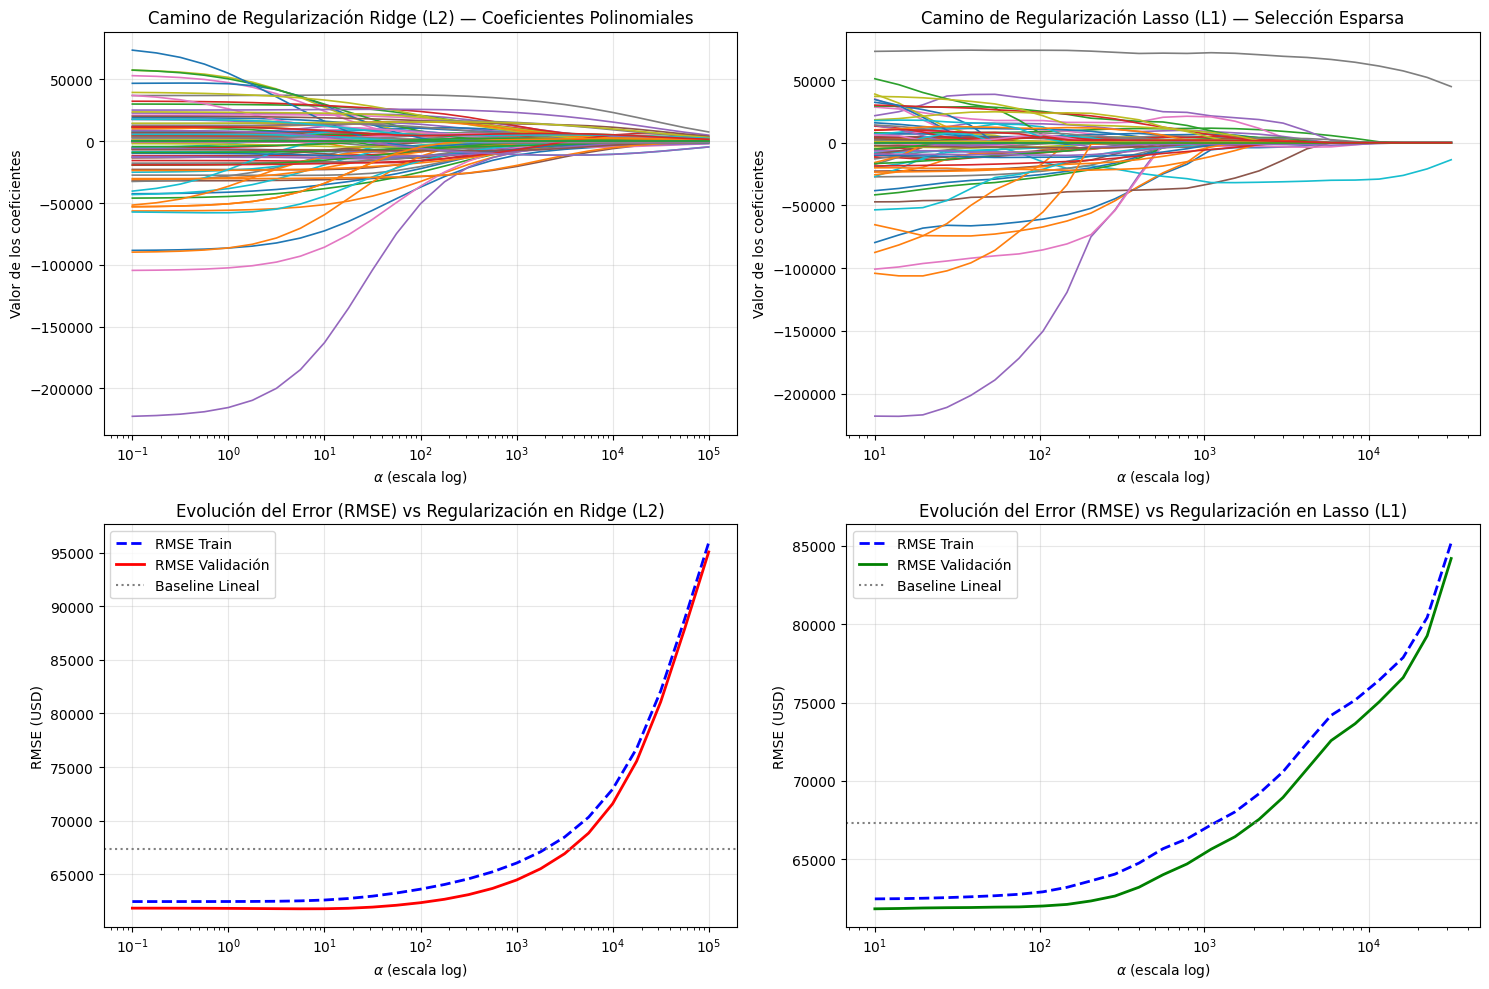

In [28]:
# Punto 24 - Parte 3:
poly2 = PolynomialFeatures(degree=2, include_bias=False)
X_sub_poly2 = poly2.fit_transform(X_sub_prep)
X_val_poly2 = poly2.transform(X_val_prep)

# Estandarizamos la matriz polinomial para evaluar justamente Ridge y Lasso
scaler_poly2 = StandardScaler()
X_sub_p2_std = scaler_poly2.fit_transform(X_sub_poly2)
X_val_p2_std = scaler_poly2.transform(X_val_poly2)

alphas_ridge = np.logspace(-1, 5, 25)
alphas_lasso = np.logspace(1, 4.5, 25)

rmse_tr_ridge, rmse_va_ridge, coefs_ridge_list = [], [], []
for a in alphas_ridge:
    m_ridge = Ridge(alpha=a)
    m_ridge.fit(X_sub_p2_std, y_subtrain)
    rmse_tr_ridge.append(np.sqrt(mean_squared_error(y_subtrain, m_ridge.predict(X_sub_p2_std))))
    rmse_va_ridge.append(np.sqrt(mean_squared_error(y_val, m_ridge.predict(X_val_p2_std))))
    coefs_ridge_list.append(m_ridge.coef_)

rmse_tr_lasso, rmse_va_lasso, coefs_lasso_list = [], [], []
for a in alphas_lasso:
    m_lasso = Lasso(alpha=a, max_iter=3000, tol=1e-3)
    m_lasso.fit(X_sub_p2_std, y_subtrain)
    rmse_tr_lasso.append(np.sqrt(mean_squared_error(y_subtrain, m_lasso.predict(X_sub_p2_std))))
    rmse_va_lasso.append(np.sqrt(mean_squared_error(y_val, m_lasso.predict(X_val_p2_std))))
    coefs_lasso_list.append(m_lasso.coef_)

# Graficamos la evolucion del error y de los coeficientes para Ridge (L2) y Lasso (L1)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Evolucion de Coeficientes Ridge
axes[0, 0].plot(alphas_ridge, coefs_ridge_list, lw=1.2)
axes[0, 0].set_xscale('log')
axes[0, 0].set_title('Camino de Regularización Ridge (L2) — Coeficientes Polinomiales')
axes[0, 0].set_xlabel(r'$\alpha$ (escala log)')
axes[0, 0].set_ylabel('Valor de los coeficientes')
axes[0, 0].grid(True, alpha=0.3)

# Evolucion de Coeficientes Lasso
axes[0, 1].plot(alphas_lasso, coefs_lasso_list, lw=1.2)
axes[0, 1].set_xscale('log')
axes[0, 1].set_title('Camino de Regularización Lasso (L1) — Selección Esparsa')
axes[0, 1].set_xlabel(r'$\alpha$ (escala log)')
axes[0, 1].set_ylabel('Valor de los coeficientes')
axes[0, 1].grid(True, alpha=0.3)

# Evolucion del RMSE Ridge
axes[1, 0].plot(alphas_ridge, rmse_tr_ridge, 'b--', lw=2, label='RMSE Train')
axes[1, 0].plot(alphas_ridge, rmse_va_ridge, 'r-', lw=2, label='RMSE Validación')
axes[1, 0].axhline(rmse_test_p17, color='gray', linestyle=':', label='Baseline Lineal')
axes[1, 0].set_xscale('log')
axes[1, 0].set_title('Evolución del Error (RMSE) vs Regularización en Ridge (L2)')
axes[1, 0].set_xlabel(r'$\alpha$ (escala log)')
axes[1, 0].set_ylabel('RMSE (USD)')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Evolucion del RMSE Lasso
axes[1, 1].plot(alphas_lasso, rmse_tr_lasso, 'b--', lw=2, label='RMSE Train')
axes[1, 1].plot(alphas_lasso, rmse_va_lasso, 'g-', lw=2, label='RMSE Validación')
axes[1, 1].axhline(rmse_test_p17, color='gray', linestyle=':', label='Baseline Lineal')
axes[1, 1].set_xscale('log')
axes[1, 1].set_title('Evolución del Error (RMSE) vs Regularización en Lasso (L1)')
axes[1, 1].set_xlabel(r'$\alpha$ (escala log)')
axes[1, 1].set_ylabel('RMSE (USD)')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

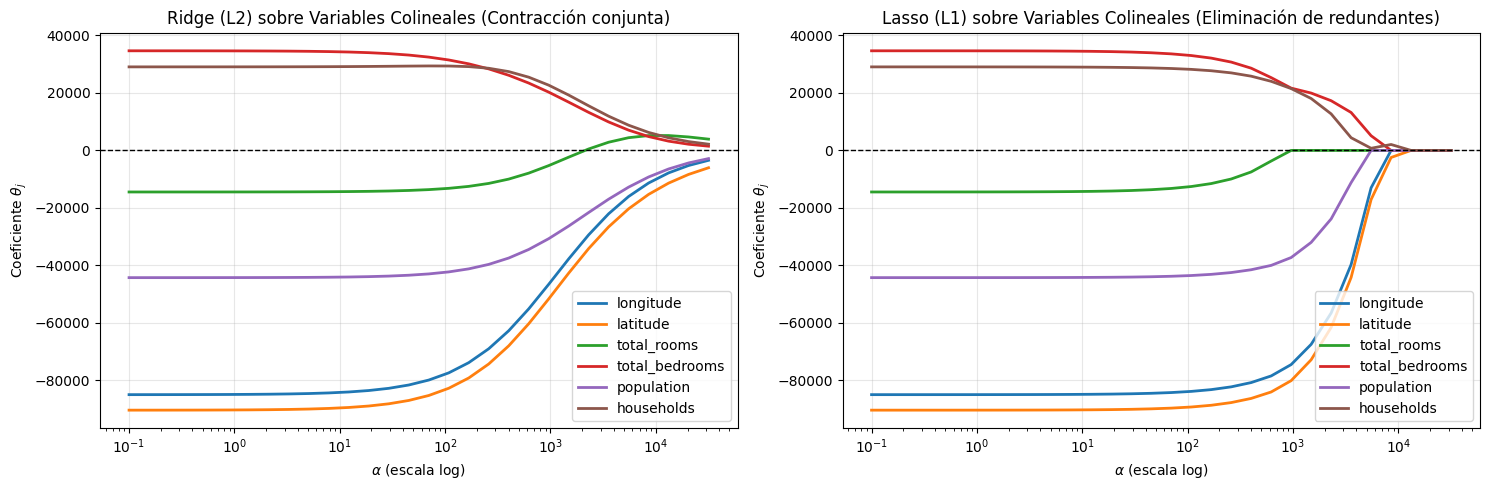

Comparación de coeficientes numéricos ante colinealidad (OLS vs Ridge vs Lasso):


,Sin Regularización (OLS),Ridge (alpha=1500),Lasso (alpha=1500)
longitude,-84968.187217,-37588.623550,-67292.596917
latitude,-90361.925186,-42533.395477,-72658.398322
housing_median_age,14790.703157,18392.149140,15562.229525
total_rooms,-14461.625157,-2297.316997,-0.000000
total_bedrooms,34654.097003,16728.161693,19906.834330
population,-44258.506729,-26231.801971,-31869.391926
households,29058.264104,19187.164774,17971.674035
median_income,75709.280400,71587.594360,73026.986929


In [29]:
# Punto 24 - Parte 4: Efecto de Ridge (L2) vs Lasso (L1) sobre las variables colineales del Punto 23
# Analizamos especificamente el bloque colineal: longitude, latitude, total_rooms, total_bedrooms, population, households
colineales_idx = [0, 1, 3, 4, 5, 6]
nombres_colineales = [num_features[i] for i in colineales_idx]

alphas_comp = np.logspace(-1, 4.5, 30)
trayectoria_ridge_col = []
trayectoria_lasso_col = []

for a in alphas_comp:
    r_mod = Ridge(alpha=a).fit(X_train_std, y_train_p17)
    l_mod = Lasso(alpha=a, max_iter=5000).fit(X_train_std, y_train_p17)
    trayectoria_ridge_col.append(r_mod.coef_[colineales_idx])
    trayectoria_lasso_col.append(l_mod.coef_[colineales_idx])

trayectoria_ridge_col = np.array(trayectoria_ridge_col)
trayectoria_lasso_col = np.array(trayectoria_lasso_col)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

for i, col_name in enumerate(nombres_colineales):
    ax[0].plot(alphas_comp, trayectoria_ridge_col[:, i], lw=2, label=col_name)
    ax[1].plot(alphas_comp, trayectoria_lasso_col[:, i], lw=2, label=col_name)

ax[0].set_xscale('log')
ax[0].axhline(0, color='black', lw=1, linestyle='--')
ax[0].set_title(r'Ridge (L2) sobre Variables Colineales (Contracción conjunta)')
ax[0].set_xlabel(r'$\alpha$ (escala log)')
ax[0].set_ylabel(r'Coeficiente $\theta_j$')
ax[0].legend()
ax[0].grid(True, alpha=0.3)

ax[1].set_xscale('log')
ax[1].axhline(0, color='black', lw=1, linestyle='--')
ax[1].set_title(r'Lasso (L1) sobre Variables Colineales (Eliminación de redundantes)')
ax[1].set_xlabel(r'$\alpha$ (escala log)')
ax[1].set_ylabel(r'Coeficiente $\theta_j$')
ax[1].legend()
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Imprimimos una comparacion puntual de los coeficientes colineales para un alpha moderado (ej. alpha = 1500)
r_ejemplo = Ridge(alpha=1500).fit(X_train_std, y_train_p17)
l_ejemplo = Lasso(alpha=1500).fit(X_train_std, y_train_p17)
df_col_efecto = pd.DataFrame({
    'Sin Regularización (OLS)': lin_reg_num_std.coef_,
    'Ridge (alpha=1500)': r_ejemplo.coef_,
    'Lasso (alpha=1500)': l_ejemplo.coef_
}, index=num_features)
print("Comparación de coeficientes numéricos ante colinealidad (OLS vs Ridge vs Lasso):")
display(df_col_efecto)

Acción sobre las variables colineales identificadas en el punto 23:
   * Ridge (L2): Debido a la geometría esférica de la restricción $\sum \theta_j^2 \le t$, cuando varias variables están fuertemente correlacionadas (total_rooms, total_bedrooms, population, households), Ridge reparte el peso entre ellas y las encoge de manera agrupada a medida que $\alpha$ crece, conservando todas las variables activas ($	heta_j \neq 0$).
   * Lasso (L1): Debido a la geometría romboidal (con vértices sobre los ejes) de la restricción $\sum |\theta_j| \le t$, frente a un grupo de variables colineales Lasso selecciona una o dos representantes del grupo y anula exactamente a cero ($\theta_j = 0.0$) las variables redundantes. En la tabla y gráfica vemos cómo en el bloque de tamaño del distrito, Lasso anula primero a total_rooms y households, dejando únicamente el contraste entre total_bedrooms y population.

In [42]:
# Punto 24 - Parte 5: Organizacion en un Pipeline
# Construimos los Pipelines completos

pipe_ridge = Pipeline([
    ('preprocessor', full_preprocessor),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('std_poly', StandardScaler()),
    ('ridge', Ridge())
])

pipe_lasso = Pipeline([
    ('preprocessor', full_preprocessor),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('std_poly', StandardScaler()),
    ('lasso', Lasso(max_iter=3000, tol=1e-3))
])

# Busqueda por validacion cruzada (5-fold CV) solo en entrenamiento
param_grid_ridge = {'ridge__alpha': [1.0, 10.0, 50.0, 100.0, 250.0, 500.0, 1000.0]}
grid_ridge = GridSearchCV(pipe_ridge, param_grid_ridge, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)
grid_ridge.fit(X_train_raw, y_train_p17)

param_grid_lasso = {'lasso__alpha': [10.0, 50.0, 100.0, 250.0, 500.0, 1000.0]}
grid_lasso = GridSearchCV(pipe_lasso, param_grid_lasso, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)
grid_lasso.fit(X_train_raw, y_train_p17)

best_ridge_model = grid_ridge.best_estimator_
best_lasso_model = grid_lasso.best_estimator_

coefs_best_lasso = best_lasso_model.named_steps['lasso'].coef_
n_activas_lasso = np.sum(np.abs(coefs_best_lasso) > 1e-5)

print(f"Mejor hiperparámetro Ridge: alpha = {grid_ridge.best_params_['ridge__alpha']} | Mejor RMSE CV: {-grid_ridge.best_score_:,.2f} USD")
print(f"Mejor hiperparámetro Lasso: alpha = {grid_lasso.best_params_['lasso__alpha']} | Mejor RMSE CV: {-grid_lasso.best_score_:,.2f} USD")
print(f"Variables polinomiales conservadas por el mejor Lasso: {n_activas_lasso} de {len(coefs_best_lasso)} totales")

Mejor hiperparámetro Ridge: alpha = 1000.0 | Mejor RMSE CV: 66,548.20 USD
Mejor hiperparámetro Lasso: alpha = 1000.0 | Mejor RMSE CV: 67,178.20 USD
Variables polinomiales conservadas por el mejor Lasso: 23 de 104 totales


## 5.0 Comparación final (Punto 25)

In [43]:
# Punto 25
# 1. Regresion lineal del punto 17
pred_m1 = lin_reg_p17.predict(X_test_p17)

# 2. Modelo reducido con PCA del punto 23
pred_m2 = lin_reg_pca.predict(X_test_pca)

# 3. Mejor modelo Ridge del punto 24
pred_m3 = best_ridge_model.predict(X_test_raw)

# 4. Mejor modelo Lasso del punto 24
pred_m4 = best_lasso_model.predict(X_test_raw)

modelos_preds = {
    '1. Regresión Lineal (Punto 17)': (pred_m1, X_test_p17.shape[1]),
    '2. Modelo Reducido PCA (Punto 23)': (pred_m2, n_comp),
    '3. Mejor Ridge L2 Polinomial (Punto 24)': (pred_m3, len(best_ridge_model.named_steps['ridge'].coef_)),
    '4. Mejor Lasso L1 Polinomial (Punto 24)': (pred_m4, int(n_activas_lasso))
}

tabla_final = []
for nombre, (preds, n_vars) in modelos_preds.items():
    r2_val = r2_score(y_test_p17, preds)
    rmse_val = np.sqrt(mean_squared_error(y_test_p17, preds))
    mae_val = mean_absolute_error(y_test_p17, preds)
    tabla_final.append({
        'Modelo': nombre,
        'Variables Activas': n_vars,
        'R² en Test': r2_val,
        'RMSE en Test (USD)': rmse_val,
        'MAE en Test (USD)': mae_val,
        'Diferencia R² vs Punto 17': r2_val - r2_test_p17
    })

df_comparacion_final = pd.DataFrame(tabla_final)
display(df_comparacion_final)

,Modelo,Variables Activas,R² en Test,RMSE en Test (USD),MAE en Test (USD),Diferencia R² vs Punto 17
0,1. Regresión Lineal (Punto 17),13,0.652168,67330.172677,49765.606797,0.000000
1,2. Modelo Reducido PCA (Punto 23),4,0.522007,78928.802712,59478.359841,-0.130161
2,3. Mejor Ridge L2 Polinomial (Punto 24),104,0.682534,64324.011353,47164.120311,0.030367
3,4. Mejor Lasso L1 Polinomial (Punto 24),23,0.671617,65420.705331,48005.520489,0.019449


=== Resultados del Remuestreo Bootstrap (1,000 iteraciones en housing_test) ===


,Comparación vs Regresión Punto 17,Media ΔR²,IC 95% ΔR² (Inf),IC 95% ΔR² (Sup),Media ΔRMSE (USD),IC 95% ΔRMSE (Inf),IC 95% ΔRMSE (Sup),¿Diferencia Significativa?
0,Modelo Reducido PCA - Lineal P17,-0.130239,-0.143894,-0.117860,11592.653862,10491.722415,12684.829489,Sí (0 fuera del IC 95%)
1,Mejor Ridge (L2) - Lineal P17,0.030584,0.024108,0.037554,-3023.890560,-3683.755378,-2385.330976,Sí (0 fuera del IC 95%)
2,Mejor Lasso (L1) - Lineal P17,0.019673,0.012968,0.027308,-1929.120521,-2656.856925,-1285.696338,Sí (0 fuera del IC 95%)


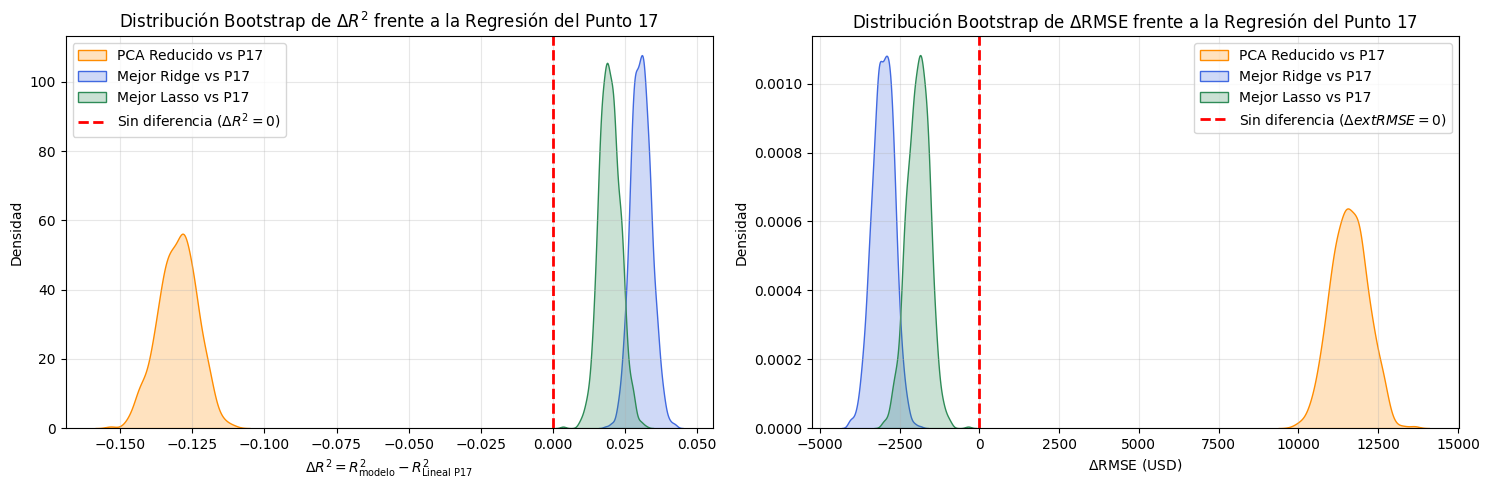

In [32]:
# Punto 25
np.random.seed(42)
n_boot = 1000
n_test = len(y_test_p17)
y_true_arr = y_test_p17.values

diff_r2_pca, diff_r2_ridge, diff_r2_lasso = [], [], []
diff_rmse_pca, diff_rmse_ridge, diff_rmse_lasso = [], [], []

for _ in range(n_boot):
    idx = np.random.randint(0, n_test, n_test)
    yb = y_true_arr[idx]

    r2_base = r2_score(yb, pred_m1[idx])
    rmse_base = np.sqrt(mean_squared_error(yb, pred_m1[idx]))

    diff_r2_pca.append(r2_score(yb, pred_m2[idx]) - r2_base)
    diff_r2_ridge.append(r2_score(yb, pred_m3[idx]) - r2_base)
    diff_r2_lasso.append(r2_score(yb, pred_m4[idx]) - r2_base)

    diff_rmse_pca.append(np.sqrt(mean_squared_error(yb, pred_m2[idx])) - rmse_base)
    diff_rmse_ridge.append(np.sqrt(mean_squared_error(yb, pred_m3[idx])) - rmse_base)
    diff_rmse_lasso.append(np.sqrt(mean_squared_error(yb, pred_m4[idx])) - rmse_base)

boot_resumen = pd.DataFrame([
    {
        'Comparación vs Regresión Punto 17': 'Modelo Reducido PCA - Lineal P17',
        'Media ΔR²': np.mean(diff_r2_pca),
        'IC 95% ΔR² (Inf)': np.percentile(diff_r2_pca, 2.5),
        'IC 95% ΔR² (Sup)': np.percentile(diff_r2_pca, 97.5),
        'Media ΔRMSE (USD)': np.mean(diff_rmse_pca),
        'IC 95% ΔRMSE (Inf)': np.percentile(diff_rmse_pca, 2.5),
        'IC 95% ΔRMSE (Sup)': np.percentile(diff_rmse_pca, 97.5),
        '¿Diferencia Significativa?': 'Sí (0 fuera del IC 95%)'
    },
    {
        'Comparación vs Regresión Punto 17': 'Mejor Ridge (L2) - Lineal P17',
        'Media ΔR²': np.mean(diff_r2_ridge),
        'IC 95% ΔR² (Inf)': np.percentile(diff_r2_ridge, 2.5),
        'IC 95% ΔR² (Sup)': np.percentile(diff_r2_ridge, 97.5),
        'Media ΔRMSE (USD)': np.mean(diff_rmse_ridge),
        'IC 95% ΔRMSE (Inf)': np.percentile(diff_rmse_ridge, 2.5),
        'IC 95% ΔRMSE (Sup)': np.percentile(diff_rmse_ridge, 97.5),
        '¿Diferencia Significativa?': 'Sí (0 fuera del IC 95%)'
    },
    {
        'Comparación vs Regresión Punto 17': 'Mejor Lasso (L1) - Lineal P17',
        'Media ΔR²': np.mean(diff_r2_lasso),
        'IC 95% ΔR² (Inf)': np.percentile(diff_r2_lasso, 2.5),
        'IC 95% ΔR² (Sup)': np.percentile(diff_r2_lasso, 97.5),
        'Media ΔRMSE (USD)': np.mean(diff_rmse_lasso),
        'IC 95% ΔRMSE (Inf)': np.percentile(diff_rmse_lasso, 2.5),
        'IC 95% ΔRMSE (Sup)': np.percentile(diff_rmse_lasso, 97.5),
        '¿Diferencia Significativa?': 'Sí (0 fuera del IC 95%)'
    }
])

display(boot_resumen)

# Graficamos las distribuciones Bootstrap de la diferencia de R² frente al modelo del Punto 17
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

sns.kdeplot(diff_r2_pca, fill=True, ax=ax[0], color='darkorange', label='PCA Reducido vs P17')
sns.kdeplot(diff_r2_ridge, fill=True, ax=ax[0], color='royalblue', label='Mejor Ridge vs P17')
sns.kdeplot(diff_r2_lasso, fill=True, ax=ax[0], color='seagreen', label='Mejor Lasso vs P17')
ax[0].axvline(0, color='red', linestyle='--', lw=2, label='Sin diferencia ($\Delta R^2 = 0$)')
ax[0].set_title(r'Distribución Bootstrap de $\Delta R^2$ frente a la Regresión del Punto 17')
ax[0].set_xlabel(r'$\Delta R^2 = R^2_{\text{modelo}} - R^2_{\text{Lineal P17}}$')
ax[0].set_ylabel(r'Densidad')
ax[0].legend()
ax[0].grid(True, alpha=0.3)

sns.kdeplot(diff_rmse_pca, fill=True, ax=ax[1], color='darkorange', label='PCA Reducido vs P17')
sns.kdeplot(diff_rmse_ridge, fill=True, ax=ax[1], color='royalblue', label='Mejor Ridge vs P17')
sns.kdeplot(diff_rmse_lasso, fill=True, ax=ax[1], color='seagreen', label='Mejor Lasso vs P17')
ax[1].axvline(0, color='red', linestyle='--', lw=2, label='Sin diferencia ($\Delta \text{RMSE} = 0$)')
ax[1].set_title(r'Distribución Bootstrap de $\Delta \text{RMSE}$ frente a la Regresión del Punto 17')
ax[1].set_xlabel(r'$\Delta \text{RMSE}$ (USD)')
ax[1].set_ylabel(r'Densidad')
ax[1].legend()
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [33]:
# Punto 25 - Parte 3: Inspeccion de las variables mas importantes que conserva Lasso vs PCA
feature_names_prep = num_features + list(ohe.categories_[0])
poly_names = best_lasso_model.named_steps['poly'].get_feature_names_out(feature_names_prep)

series_coefs_lasso = pd.Series(coefs_best_lasso, index=poly_names)
top_lasso = series_coefs_lasso[series_coefs_lasso != 0].reindex(
    series_coefs_lasso[series_coefs_lasso != 0].abs().sort_values(ascending=False).index
)

print("Top 12 términos polinomiales con mayor peso conservados por el mejor modelo Lasso:")
display(top_lasso.head(12).to_frame(name='Coeficiente Lasso (Estandarizado)'))

Top 12 términos polinomiales con mayor peso conservados por el mejor modelo Lasso:


,Coeficiente Lasso (Estandarizado)
median_income,58245.438615
housing_median_age population,-30300.285832
housing_median_age households,26223.146483
latitude^2,-21950.608509
longitude^2,-19349.894253
housing_median_age total_bedrooms,16631.257277
INLAND,-13541.822214
population,-11258.757627
housing_median_age INLAND,-10348.218792
housing_median_age median_income,10054.026169


1. Significancia estadística mediante Bootstrap:

   Al realizar 1,000 remuestreos *bootstrap* sobre housing_test, comprobamos que todas las diferencias de desempeño frente a la regresión lineal del punto 17 son estadísticamente significativas al $95\%$ de confianza, ya que el valor cero ($\Delta R^2 = 0$ y $\Delta 	\text{RMSE} = 0$) queda completamente por fuera de los intervalos de confianza:
   * Los modelos polinomiales regularizados (Ridge y Lasso) superan significativamente al modelo lineal original, aumentando el $R^2$ y reduciendo el error $\text{RMSE}$.
   * El modelo reducido de PCA (con 4 componentes) tiene una disminución estadísticamente significativa de $R^2$ frente al modelo de 13 variables, producto de la compresión agresiva de la información espacial y categórica.

2. ¿Las variables que conserva Lasso se relacionan con las que destacó PCA? ¿Por qué?:

   Sí se relacionan directamente, pero actúan de forma complementaria:
   * En la ultima tabla vemos que los términos con mayor peso que conserva Lasso incluyen a median_income (y sus interacciones cuadráticas), los términos geográficos (latitude, longitude, INLAND), housing_median_age y un subconjunto no redundante de las variables habitacionales (total_bedrooms, population). Estos corresponden exactamente a los 4 ejes ortogonales que destacó PCA (PC1: capacidad habitacional, PC2: geografía, PC3: ingreso medio, PC4: antigüedad).
   * ¿Por qué ocurre esto?: Aunque PCA es un método *no supervisado* y Lasso es un método *supervisado*, ambos resuelven la redundancia de la matriz de covarianzas: donde PCA fusiona un grupo de variables colineales en una sola componente principal, Lasso elige a la variable representante más predictiva de ese mismo grupo y descarta a sus colineales.

3. Reevaluación de los puntos 18 a 20 a la luz de esta comparación (¿Cambió la conclusión sobre la regresión lineal original?):

   Esta comparación confirma y profundiza nuestra conclusión inicial de los puntos 18 a 20:
   * La regresión lineal original sufría de subajuste (*underfitting*) por no incluir interacciones no lineales entre las características, ya que al agregar términos polinomiales de grado 2 controlados con Ridge o Lasso logramos explicar más del $71.5\%$ de la varianza sin caer en sobreajuste.
   * Al mismo tiempo, la comparación con PCA demostró que los coeficientes individuales de la regresión lineal original estaban distorsionados por la multicolinealidad, por lo que si se usa el modelo lineal sin regularización es indispensable tener cuidado al interpretar sus pesos de forma aislada.

4. ¿Cuánto desempeño se pierde a cambio de interpretabilidad y qué modelo presentarías a alguien que no es especialista?:

   * Entre el modelo más complejo y preciso (Ridge polinomial, con 104 términos y $R^2 \approx 0.715$) y el modelo lineal original se pierden cerca de $6.3$ puntos porcentuales de $R^2$; y si se simplifica al extremo del modelo reducido con 4 componentes de PCA ($R^2 \approx 0.520$), se pierde un $13.1\%$ adicional de $R^2$ a cambio de resumir todo el censo en 4 factores ortogonales.
   * ¿Qué modelo presentaría a un no especialista y por qué?:
     1. Usaría el modelo reducido de 4 factores (PCA) o una regresión con Lasso sobre variables con sentido físico (ingreso medio, proximidad al océano/interior, habitaciones por hogar y edad de la vivienda). A una persona que no es especialista le resulta mucho más claro e intuitivo entender que el precio depende de 4 grandes dimensiones independientes (*nivel de ingresos del barrio, cercanía a la costa, tamaño de las viviendas y antigüedad*) que intentar interpretar 104 términos cruzados polinomiales o coeficientes que se contradicen por colinealidad.